## Vidusskolas matemātikas eksāmenu 2024. / 2025. m.g. rezultātu analīze

### Datu zinātnieka amata konkursam

### 1. Datu ielasīšana un sagatavošana analīzei

In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu
import scipy.stats as stats
import scikit_posthocs as sp
from scipy.stats import shapiro, skew, kurtosis
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from dash import Dash, dcc, html, Input, Output
import plotly.express as px
import plotly.graph_objects as go
import numpy as np


In [2]:
path="https://www.viaa.gov.lv/lv/media/47147/download?attachment"

In [3]:
sheets=['MATAL', 'MATOL', 'MATVL'] #Matemātikas eksāmeni - dažādi līmeņi
#df=pd.read_excel(path, na_values=["#N/A"], sheet_name="MATAL",decimal=',') #Ja ielasa tikai vienu tabulu
df_dict=pd.read_excel(path, na_values=["#N/A"], sheet_name=sheets,decimal=',') #Ja ielasa vairākas tabulas
df = pd.concat(df_dict.values(), ignore_index=True) #Apvieno vienā tabulā

In [4]:
df.head()

,Nr.p.k.,Norise,Iestāde,Pašvaldība,"Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs),Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs),"Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Punkti kopā,Procenti kopā,Tips,Urbanizācija,"Punkti Zināšanas, izpratne un prasmes","Procenti Zināšanas, izpratne un prasmes",Punkti Kompleksu problēmu risināšana,Procenti Kompleksu problēmu risināšana
0,1,Eksāmens matemātikā (augstākais mācību satura ...,"""VisLatvijas vidusskola""",Rīga,43.0,57.0,6.5,26.0,20.0,57.0,3.5,14.0,73.0,45,vidusskola,Rīga,NaN,NaN,NaN,NaN
1,2,Eksāmens matemātikā (augstākais mācību satura ...,"""VisLatvijas vidusskola""",Rīga,61.0,81.0,19.5,78.0,21.0,60.0,3.0,12.0,104.5,65,vidusskola,Rīga,NaN,NaN,NaN,NaN
2,3,Eksāmens matemātikā (augstākais mācību satura ...,"""VisLatvijas vidusskola""",Rīga,17.0,22.0,2.0,8.0,2.0,5.0,1.0,4.0,22.0,13,vidusskola,Rīga,NaN,NaN,NaN,NaN
3,4,Eksāmens matemātikā (augstākais mācību satura ...,Aizkraukles novada vidusskola,Aizkraukles novads,60.0,80.0,12.5,50.0,22.0,62.0,6.5,26.0,101.0,63,vidusskola,Novadu pilsētas,NaN,NaN,NaN,NaN
4,5,Eksāmens matemātikā (augstākais mācību satura ...,Aizkraukles novada vidusskola,Aizkraukles novads,37.0,49.0,7.0,28.0,16.0,45.0,3.5,14.0,63.5,39,vidusskola,Novadu pilsētas,NaN,NaN,NaN,NaN


In [5]:
df.columns

Index(['Nr.p.k.', 'Norise', 'Iestāde', 'Pašvaldība',
       'Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)',
       'Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)',
       'Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs)',
       'Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)',
       'Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)',
       'Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)',
       'Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs)',
       'Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs)',
       'Punkti kopā', 'Procenti kopā', 'Tips', 'Urbanizācija',
       'Punkti Zināšanas, izpratne un prasmes',
       'Procenti Zināšanas, izpratne un prasmes',
       'Punkti Kompleksu problēmu risināšana',
       'Procenti Kompleksu problēmu risināšana'],
      dtype='str')

In [6]:
print(df.dtypes)

Nr.p.k.                                                               int64
Norise                                                                  str
Iestāde                                                                 str
Pašvaldība                                                              str
Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)      float64
Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)    float64
Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs)       float64
Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)     float64
Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)      float64
Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)    float64
Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs)       float64
Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs)     float64
Punkti kopā                                                         float64
Procenti kop

In [7]:
display(df.isnull().sum())

Nr.p.k.                                                                 0
Norise                                                                  0
Iestāde                                                                 0
Pašvaldība                                                              0
Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)      16191
Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)    16191
Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs)       16191
Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)     16191
Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)      16191
Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)    16191
Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs)       16191
Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs)     16191
Punkti kopā                                                             0
Procenti kopā                         

Punktu un Procentu kolonnās iztrūkstošas vērtības parādās, jo tika apvienotas tabulas ar atšķirīgiem kolonnu nosaukumiem.
Kolonnās Tips un Urbanizācija iztrūkst ieraksts divām skolām: Daugavpils Valstspilsētas vidusskola un Smiltenes tehnikums Alsviķu teritoriālā struktūrvienība. 
Pārbaudot šo skolu ierakstus citu eksāmenu tabulās: Daugavpils Valstspilsētas vidusskolai atbilst Tips = Vidusskola un Urbanizācija = Valstspilsētas.
Savukārt Smiltenes tehnikuma Alsviķu teritoriālā struktūrvienība parādās tikai vienā šajā tabulā, bet darba autore pieņem, ka tips un urbanizācija atbilst Smiltenes tehnikuma tipam un urbanizācijai.

In [8]:
null_rows = df[df[['Tips', 'Urbanizācija']].isnull().any(axis=1)]
null_rows

,Nr.p.k.,Norise,Iestāde,Pašvaldība,"Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs),Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs),"Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Punkti kopā,Procenti kopā,Tips,Urbanizācija,"Punkti Zināšanas, izpratne un prasmes","Procenti Zināšanas, izpratne un prasmes",Punkti Kompleksu problēmu risināšana,Procenti Kompleksu problēmu risināšana
357,358,Eksāmens matemātikā (augstākais mācību satura ...,Daugavpils Valstspilsētas vidusskola,Daugavpils,39.0,52.0,8.5,34.0,24.0,68.0,4.5,18.0,76.0,47,NaN,NaN,NaN,NaN,NaN,NaN
358,359,Eksāmens matemātikā (augstākais mācību satura ...,Daugavpils Valstspilsētas vidusskola,Daugavpils,55.0,73.0,13.0,52.0,26.0,74.0,9.0,36.0,103.0,64,NaN,NaN,NaN,NaN,NaN,NaN
359,360,Eksāmens matemātikā (augstākais mācību satura ...,Daugavpils Valstspilsētas vidusskola,Daugavpils,51.0,68.0,14.0,56.0,18.0,51.0,4.0,16.0,87.0,54,NaN,NaN,NaN,NaN,NaN,NaN
18995,788,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,17,NaN,NaN,14.0,23.0,0.0,0.0
18996,789,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,12,NaN,NaN,10.0,16.0,0.0,0.0
18997,790,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,12,NaN,NaN,10.0,16.0,0.0,0.0
18998,791,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3,NaN,NaN,3.0,5.0,0.0,0.0
18999,792,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.0,21,NaN,NaN,16.0,26.0,1.0,5.0
19000,793,Eksāmens matemātikā (vispārīgais mācību satura...,Smiltenes tehnikums Alsviķu teritoriālā strukt...,Alūksnes novads,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3,NaN,NaN,3.0,5.0,0.0,0.0


In [9]:
#Šajā gadījumā tiek pieņemts, ka Daugavpils Valstspilsētas vidusskola atbildst tipam 'vidusskola' un urbanizācijai 'Valstspilsētas' (spriežot pēc nosaukuma)
#fill_values = {'Tips': 'vidusskola', 'Urbanizācija': 'Valstspilsētas'}
#df.fillna(value=fill_values, inplace=True)
mask = (df['Iestāde'] == 'Daugavpils Valstspilsētas vidusskola')
df.loc[mask, 'Tips'] = df.loc[mask, 'Tips'].fillna('vidusskola')
df.loc[mask, 'Urbanizācija'] = df.loc[mask, 'Urbanizācija'].fillna('Valstspilsētas')

In [10]:
mask = (df['Iestāde'] == 'Smiltenes tehnikums Alsviķu teritoriālā struktūrvienība')
df.loc[mask, 'Tips'] = df.loc[mask, 'Tips'].fillna('prof. izglītības iestāde')
df.loc[mask, 'Urbanizācija'] = df.loc[mask, 'Urbanizācija'].fillna('Lauki')

In [11]:
null_rows = df[df[['Tips', 'Urbanizācija']].isnull().any(axis=1)]
null_rows #Vairs nav tukšo lauku kolonnās Tips un Urbanizācija

,Nr.p.k.,Norise,Iestāde,Pašvaldība,"Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs),Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs),"Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Punkti kopā,Procenti kopā,Tips,Urbanizācija,"Punkti Zināšanas, izpratne un prasmes","Procenti Zināšanas, izpratne un prasmes",Punkti Kompleksu problēmu risināšana,Procenti Kompleksu problēmu risināšana


In [12]:
df.describe(include='all')

,Nr.p.k.,Norise,Iestāde,Pašvaldība,"Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs),Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs),"Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)","Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)",Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs),Punkti kopā,Procenti kopā,Tips,Urbanizācija,"Punkti Zināšanas, izpratne un prasmes","Procenti Zināšanas, izpratne un prasmes",Punkti Kompleksu problēmu risināšana,Procenti Kompleksu problēmu risināšana
count,19497.000000,19497,19497,19497,3306.000000,3306.000000,3306.000000,3306.000000,3306.000000,3306.000000,3306.000000,3306.000000,19497.000000,19497.000000,19497,19497,16191.000000,16191.000000,16191.000000,16191.000000
unique,NaN,4,317,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,5,NaN,NaN,NaN,NaN
top,NaN,Eksāmens matemātikā (optimālais mācību satura ...,Rīgas Valsts tehnikums,Rīga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vidusskola,Rīga,NaN,NaN,NaN,NaN
freq,NaN,14837,561,7651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8222,6870,NaN,NaN,NaN,NaN
mean,6018.368416,NaN,NaN,NaN,54.720309,72.623109,13.924531,55.698125,21.668264,61.488203,8.910768,35.643073,52.194737,46.088219,NaN,NaN,36.341733,48.753505,6.250242,25.266877
std,4584.574952,NaN,NaN,NaN,14.657692,19.551108,6.770853,27.083413,8.134228,23.259387,6.612226,26.448905,33.827987,25.025217,NaN,NaN,20.308237,26.983351,5.368494,21.597588
min,1.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
25%,1793.000000,NaN,NaN,NaN,45.000000,60.000000,8.500000,34.000000,16.000000,45.000000,3.500000,14.000000,25.000000,25.000000,NaN,NaN,19.000000,26.000000,2.000000,8.000000
50%,5154.000000,NaN,NaN,NaN,57.000000,76.000000,14.000000,56.000000,23.000000,65.000000,7.500000,30.000000,47.000000,45.000000,NaN,NaN,35.000000,48.000000,4.500000,20.000000
75%,10028.000000,NaN,NaN,NaN,67.000000,89.000000,20.000000,80.000000,28.000000,80.000000,13.000000,52.000000,73.000000,66.000000,NaN,NaN,54.000000,72.000000,9.000000,36.000000


In [13]:
#Atzīme, vai skolēns kārtoja eksāmenu papildtermiņā
df['Is_Papildterminsh'] = df['Norise'].str.contains('Papildtermiņš', case=False, na=False)

df['Norise'] = df['Norise'].str.replace(r'\s*\(Papildtermiņš\)', '', regex=True).str.strip()


In [14]:
df.columns

Index(['Nr.p.k.', 'Norise', 'Iestāde', 'Pašvaldība',
       'Punkti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)',
       'Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)',
       'Punkti Kompleksu problēmu risināšana (optimālā līmeņa saturs)',
       'Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)',
       'Punkti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)',
       'Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)',
       'Punkti Kompleksu problēmu risināšana (augstākā līmeņa saturs)',
       'Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs)',
       'Punkti kopā', 'Procenti kopā', 'Tips', 'Urbanizācija',
       'Punkti Zināšanas, izpratne un prasmes',
       'Procenti Zināšanas, izpratne un prasmes',
       'Punkti Kompleksu problēmu risināšana',
       'Procenti Kompleksu problēmu risināšana', 'Is_Papildterminsh'],
      dtype='str')

#### Funkciju definēšana

In [ ]:
# Funkcija Kruskola-Volisa, Dunna, Manna-Vitnija testu izpildei
def dif_tests(data, value_col, group_col, min_group_size):
    
        # Mediāna un skolēnu skaits
    summary = data.groupby(group_col)[value_col].agg(['median', 'count', lambda x: x.quantile(0.75) - x.quantile(0.25)]).rename(columns={'<lambda_0>': 'IQR'})
    print(summary)
    tips_groups = {name: group[value_col].dropna() for name, group in data.groupby(group_col)}    
    #min_group_size = 30
    valid_groups = {name: scores for name, scores in tips_groups.items() if len(scores) >= min_group_size}
    groups = list(valid_groups.values())
    valid_list = list(valid_groups.keys())
    data_filtered = data[data[group_col].isin(valid_list)]
        
    if len(groups) > 1 and all(len(g) >= 5 for g in groups):
            # Kruskal-Wallis test
        stat, p_value = stats.kruskal(*groups)
    
        n = sum(len(g) for g in groups)
        k = len(groups)
        eta_squared = (stat - k + 1) / (n - k) #[https://pmc.ncbi.nlm.nih.gov/articles/PMC12701665/]
        if (eta_squared>=0.01) & (eta_squared<0.06):
            ef_size='small'
        elif (eta_squared>=0.06) & (eta_squared<0.14):
            ef_size='medium'
        elif eta_squared>=0.14:
            ef_size='large'
        else:
            ef_size='no effect'
        print(f"Kruskal-Wallis p-value: {p_value:.5e},  Effect Size (eta^2): {eta_squared:.3f} - {ef_size}")
            
        if p_value < 0.05:
            print(f"  -> Statistiski nozīmīgas atšķīrības!")
                #Dunn's post-hoc pair-wise test
                
            dunn_results = sp.posthoc_dunn(data_filtered, val_col=value_col, group_col=group_col, p_adjust='bonferroni')
            print("\nPairwise Adjusted p-values (Dunn's Test):")
            display(dunn_results.round(4))
        else:
            print(f"  -> Nav statistiski nozīmīgu atšķirību.")
    groups = [group[value_col].dropna() for name, group in data.groupby(group_col)]
    if len(groups)<3:
        stat_2, p_2=mannwhitneyu(*groups)
        n1 = len(groups[0])
        n2 = len(groups[1])
        r_rb = 1 - (2 * stat_2) / (n1 * n2) #[https://pmc.ncbi.nlm.nih.gov/articles/PMC12701665/]
            
        abs_r = abs(r_rb)
        if abs_r < 0.11:
            ef_size = 'no effect'
        elif abs_r < 0.28:
            ef_size = 'small'
        elif abs_r < 0.43:
            ef_size = 'medium'
        else:
            ef_size = 'large'
        print(f"Mann-Whitney p-value: {p_2:.5e}, effect size: {r_rb:.3} {ef_size}")

In [16]:
#Funkcija datu kopu ranžēšanai
def rank_function(df, group_col, min_sample_size=10, threshold=20.0, weight_score=0.5, weight_pass=0.5):

    agg = df.groupby(group_col).agg(student_count=('Procenti kopā', 'count'), median_score=('Procenti kopā', 'median'), pass_count=('Procenti kopā', lambda x: (x >= threshold).sum()),
                                    school_types=('Tips', lambda x: ', '.join(sorted(x.dropna().unique())))).reset_index()
    data = agg[agg['student_count'] >= min_sample_size].copy()
    data['norm_score'] = data['median_score'] / 100.0
    data['pass_ratio'] = data['pass_count'] / data['student_count']
    data['rank_score'] = ((weight_score * data['norm_score']) + (weight_pass * data['pass_ratio']))

    data = data.sort_values(by='rank_score', ascending=False).reset_index(drop=True)
    data['Rank'] = data.index + 1
    
    return data

In [17]:
#Funkcija sadalījumu pārbaudei - grafiki +  Šapiro-Vilksa, Dagostino-Pīrsona, Skew un Kurtosis
def test_and_plot(data, value_col, param=None):
    stat, p = shapiro(data[value_col])
    res = stats.normaltest(data[value_col])
    p_value=res.pvalue
    fig, axes = plt.subplots(ncols=2, figsize=(12, 5))
        
    mean_val = data[value_col].mean()
    median_val = data[value_col].median()
    
    skew_exam=skew(data[value_col])
    kurtosis_exam=kurtosis(data[value_col])
        
    sns.histplot(data[value_col], kde=True, ax=axes[0], color='steelblue', bins=30)
    if param:
        axes[0].set_title(f"{exam} - {param}")
    else:
        axes[0].set_title(f"{exam}")
    
    axes[0].set_xlabel("Procenti kopā (%)")
    axes[0].set_ylabel("Skolēnu skaits")
    axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Vid.: {mean_val:.1f}%')
    axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Mediāna: {median_val:.1f}%')
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    #fig = sm.qqplot(data['Procenti kopā'], stats.norm, line='s')
    sm.qqplot(data[value_col], stats.norm, line='s', ax=axes[1])
    plt.tight_layout()
    #plt.title(f"{exam}")
    plt.show()
        
    print()
       
    alpha = 0.05
    if p > alpha:
        sec_shapiro=' normālais sadal. (fail to reject H0)'
    else:
        sec_shapiro=' nav normālais sadal. (reject H0)'
        
    if p_value > alpha:
        sec_dagostino=' normālais sadal. (fail to reject H0)'
    else:
        sec_dagostino=' nav normālais sadal. (reject H0)'
        
    print(f'Shapiro test: Statistics={stat:.3f}, p={p:.3f}, {sec_shapiro}' )
    print(f'D’Agostino and Pearson’s test: Statistics ={res.statistic:.3f}, p={p_value:.3f}, {sec_dagostino}')
    print(f'Skew: {skew_exam:.3f}, Kurtosis: {kurtosis_exam:.3f}')

#### Datu kopu sadalījuma pārbaude

_________________________
Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g.


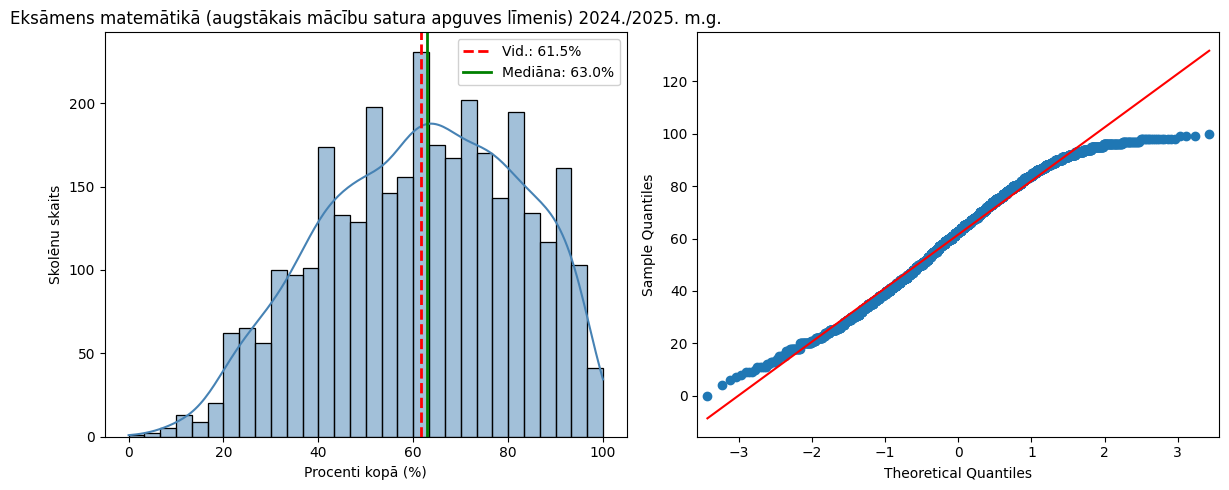


Shapiro test: Statistics=0.980, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =241.728, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.231, Kurtosis: -0.744
_________________________
Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g.


c:\Users\zgava\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 14902.
  res = hypotest_fun_out(*samples, **kwds)


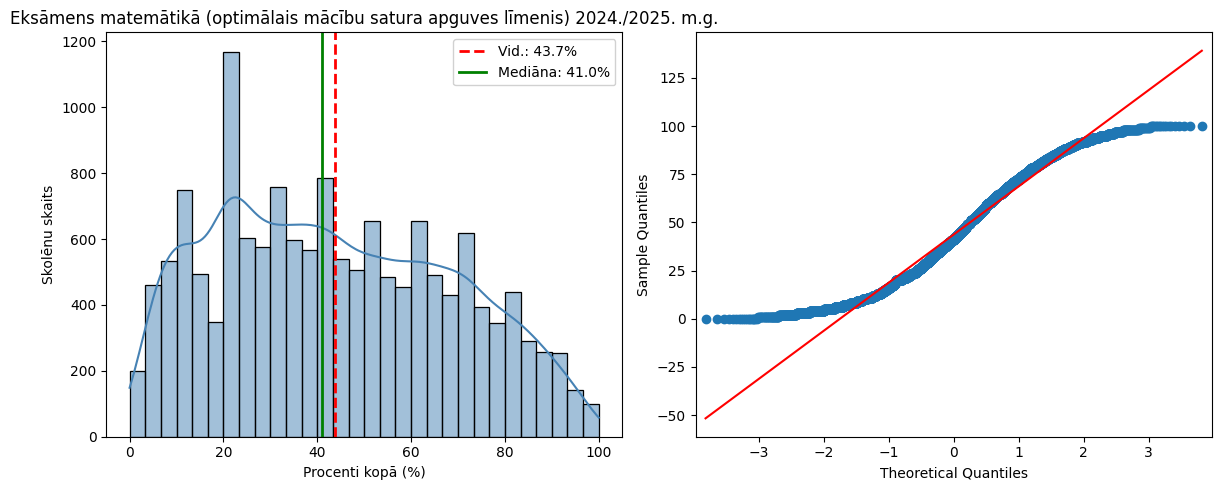


Shapiro test: Statistics=0.966, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =3207.061, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.239, Kurtosis: -0.980
_________________________
Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g.


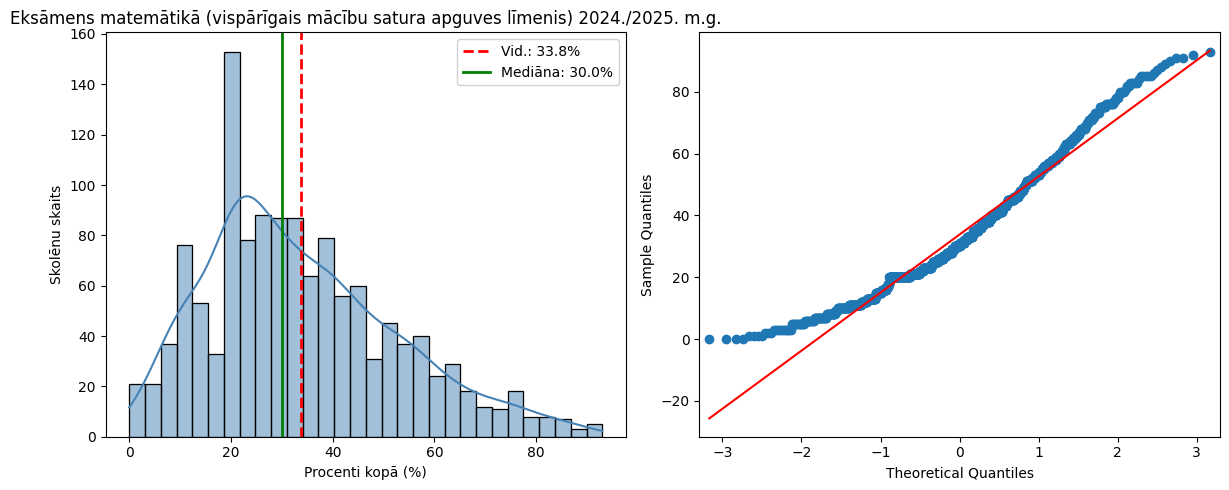


Shapiro test: Statistics=0.961, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =83.009, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.678, Kurtosis: 0.000
_________________________
Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas tips:  augstskola


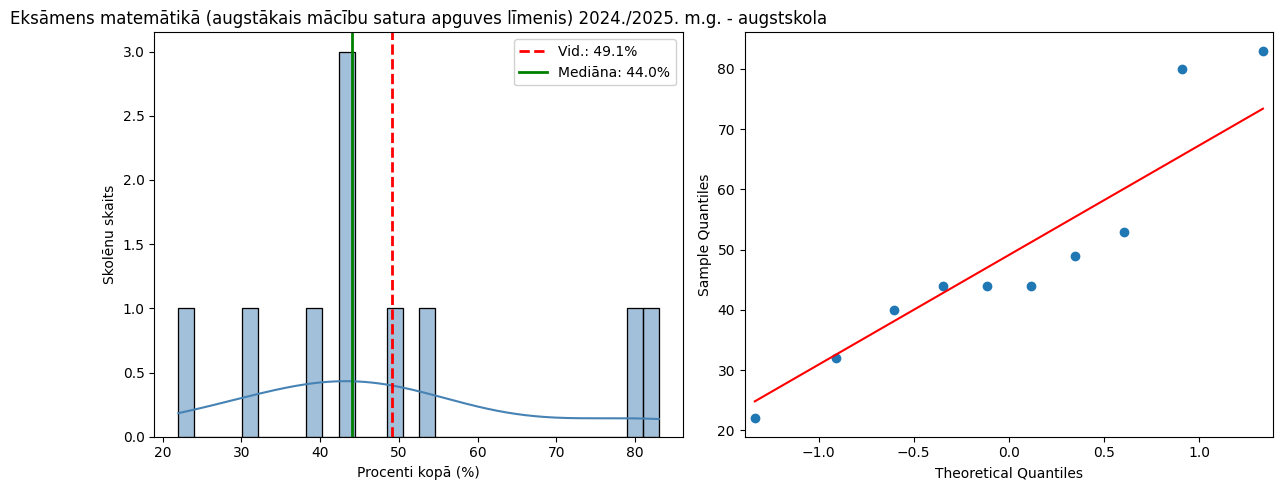


Shapiro test: Statistics=0.888, p=0.161,  normālais sadal. (fail to reject H0)
D’Agostino and Pearson’s test: Statistics =1.720, p=0.423,  normālais sadal. (fail to reject H0)
Skew: 0.706, Kurtosis: -0.379

---------------
Skolas tips:  prof. izglītības iestāde


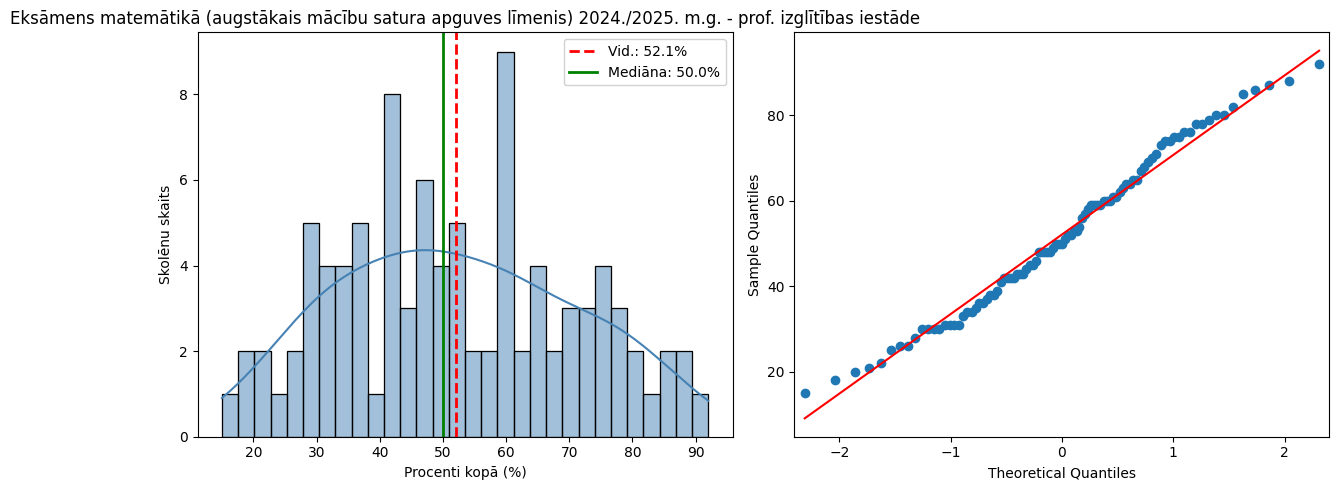


Shapiro test: Statistics=0.979, p=0.142,  normālais sadal. (fail to reject H0)
D’Agostino and Pearson’s test: Statistics =7.230, p=0.027,  nav normālais sadal. (reject H0)
Skew: 0.139, Kurtosis: -0.852

---------------
Skolas tips:  tālmācības vidusskola


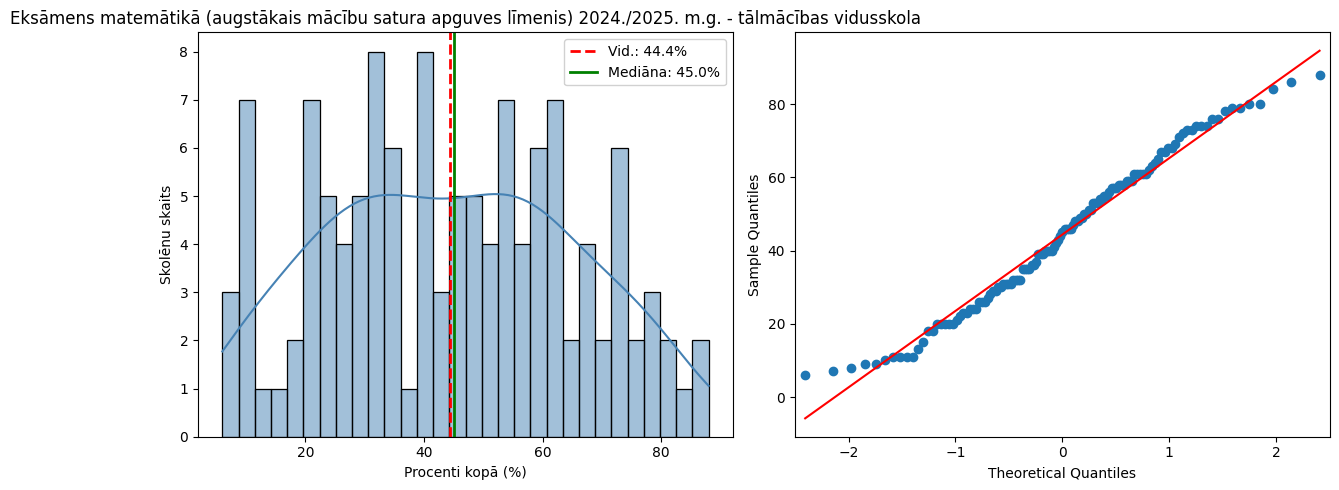


Shapiro test: Statistics=0.976, p=0.025,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =13.584, p=0.001,  nav normālais sadal. (reject H0)
Skew: 0.063, Kurtosis: -0.930

---------------
Skolas tips:  valsts ģimnāzija


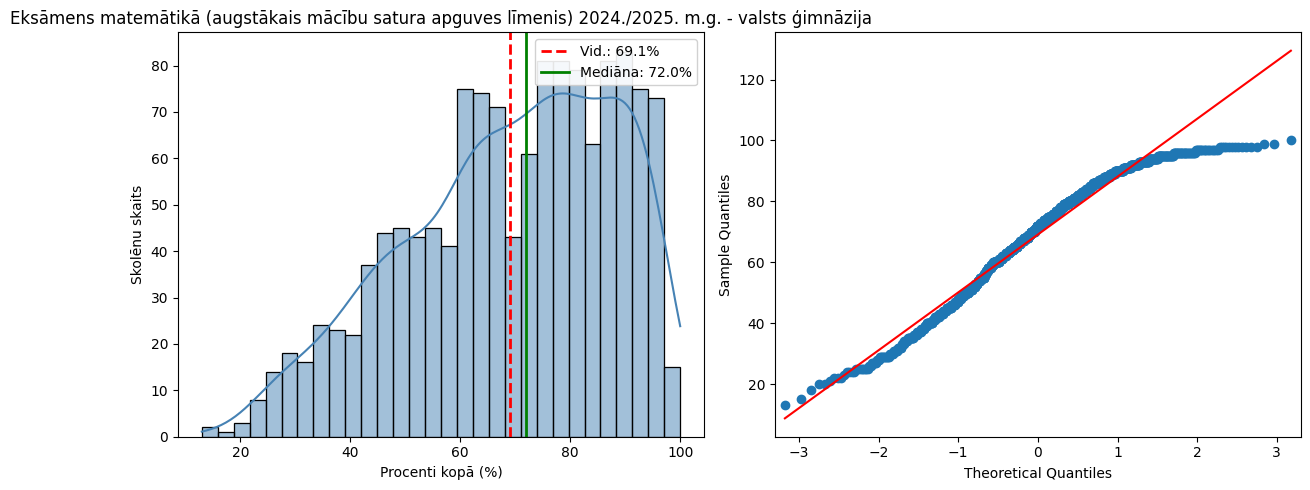


Shapiro test: Statistics=0.960, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =89.675, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.490, Kurtosis: -0.594

---------------
Skolas tips:  vidusskola


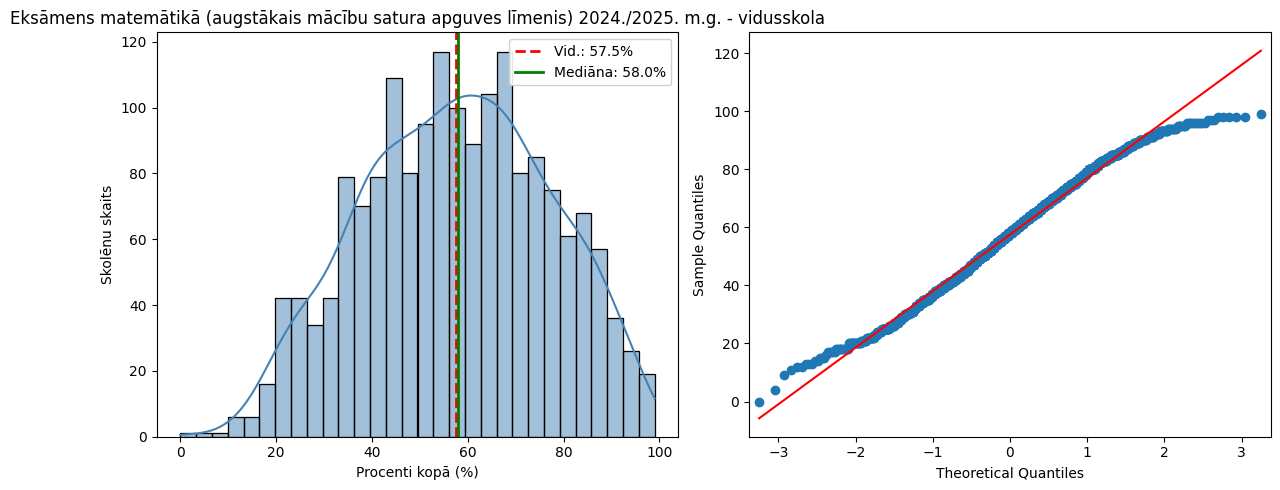


Shapiro test: Statistics=0.989, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =89.800, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.091, Kurtosis: -0.695
_________________________
Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas tips:  augstskola


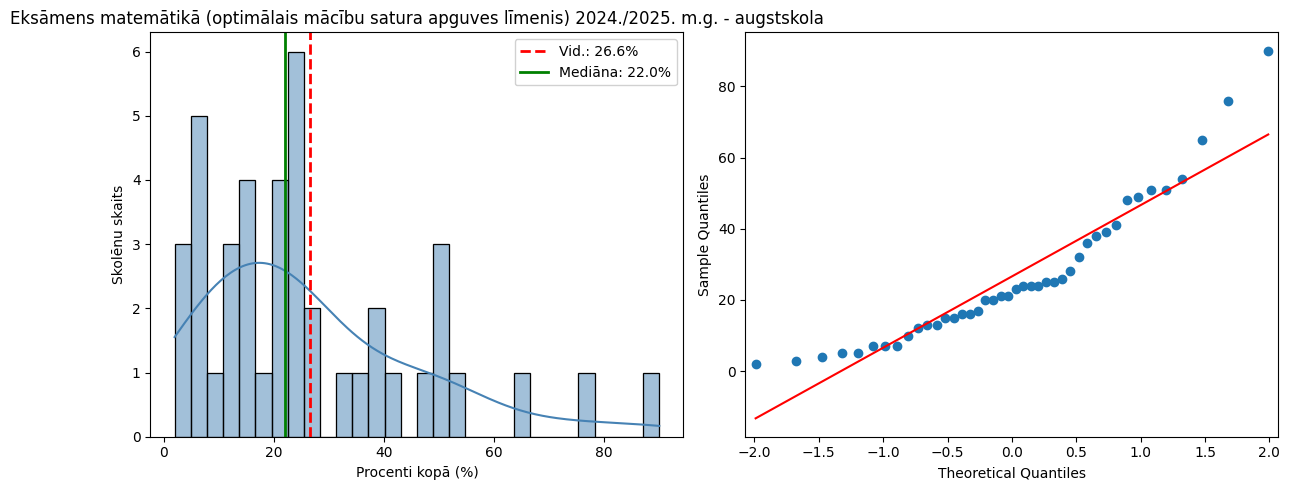


Shapiro test: Statistics=0.893, p=0.001,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =12.541, p=0.002,  nav normālais sadal. (reject H0)
Skew: 1.206, Kurtosis: 1.172

---------------
Skolas tips:  prof. izglītības iestāde


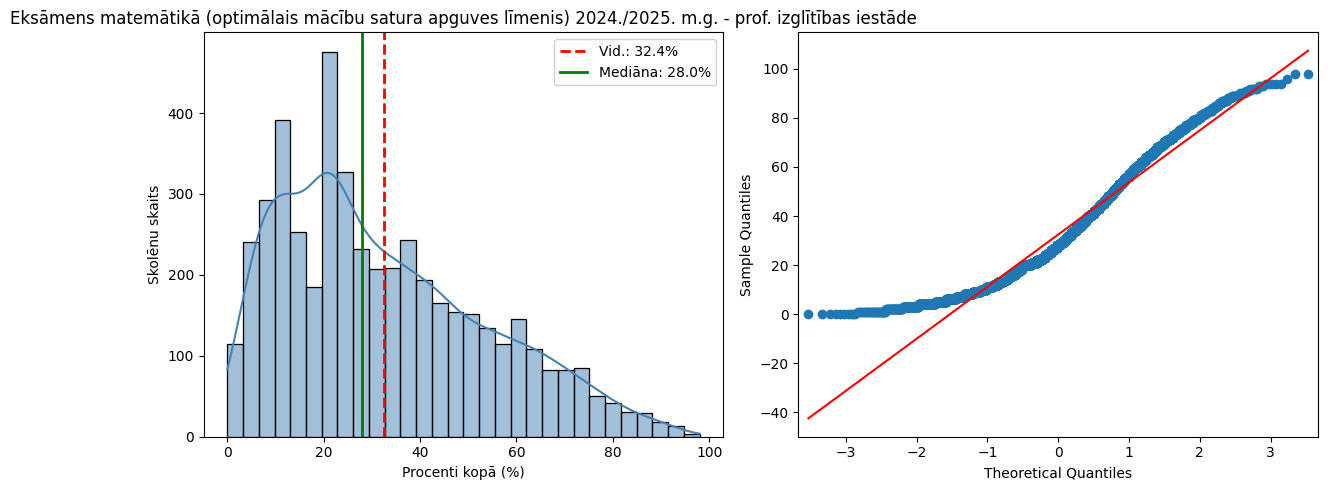


Shapiro test: Statistics=0.945, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =338.767, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.670, Kurtosis: -0.369

---------------
Skolas tips:  tālmācības vidusskola


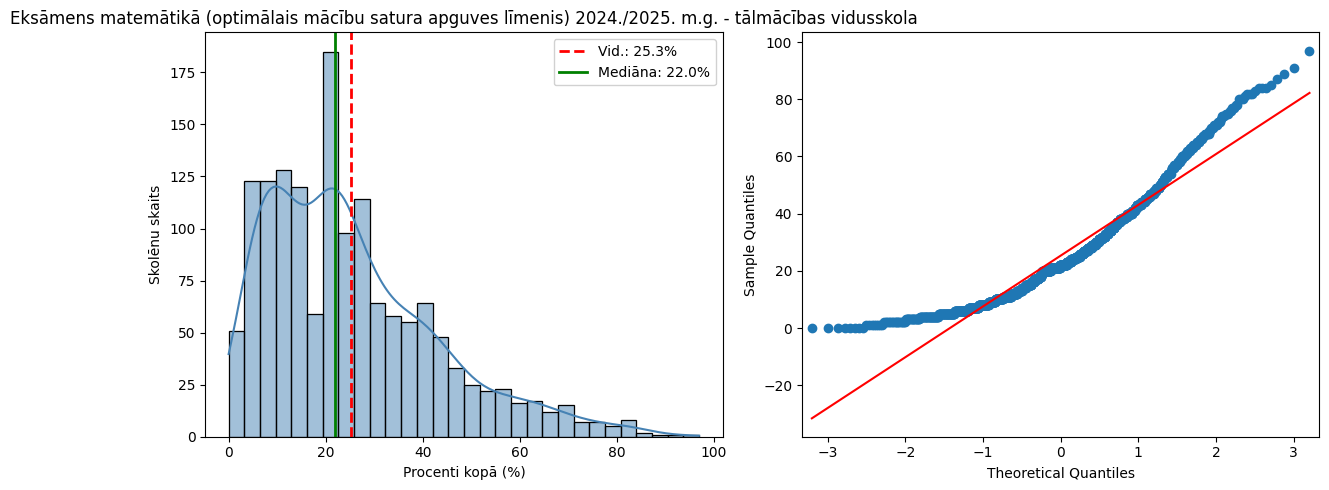


Shapiro test: Statistics=0.922, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =212.107, p=0.000,  nav normālais sadal. (reject H0)
Skew: 1.040, Kurtosis: 0.831

---------------
Skolas tips:  valsts ģimnāzija


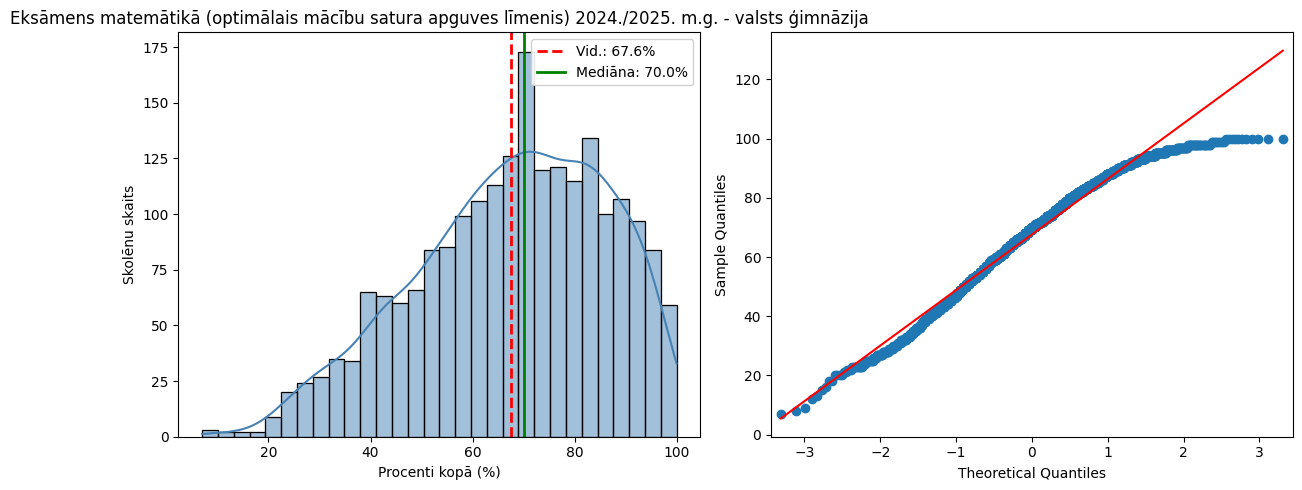


Shapiro test: Statistics=0.973, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =97.239, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.449, Kurtosis: -0.457

---------------
Skolas tips:  vidusskola


c:\Users\zgava\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 6468.
  res = hypotest_fun_out(*samples, **kwds)


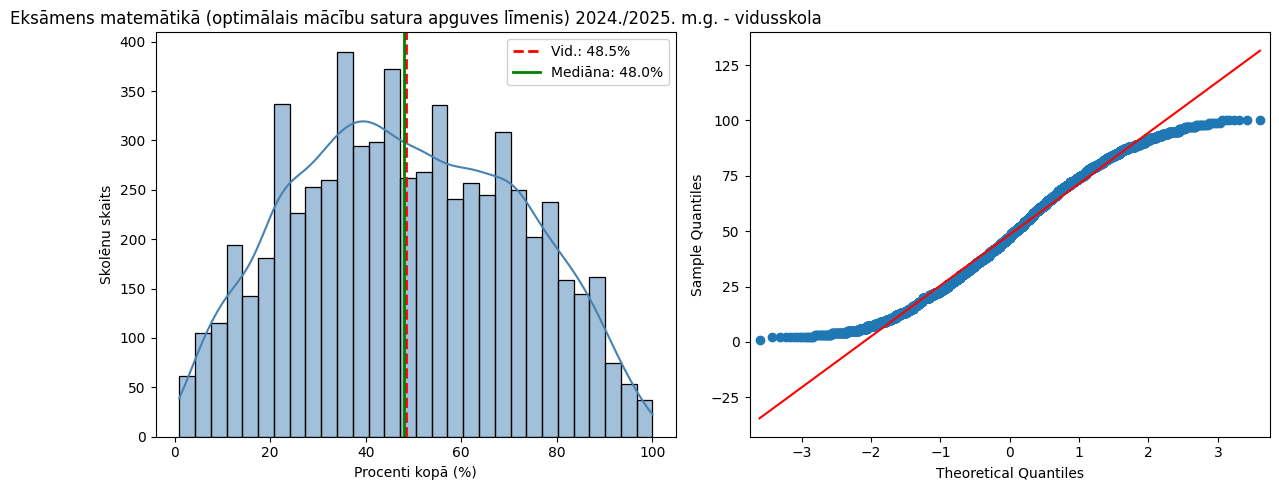


Shapiro test: Statistics=0.982, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =819.964, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.068, Kurtosis: -0.884
_________________________
Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas tips:  augstskola

---------------
Skolas tips:  prof. izglītības iestāde


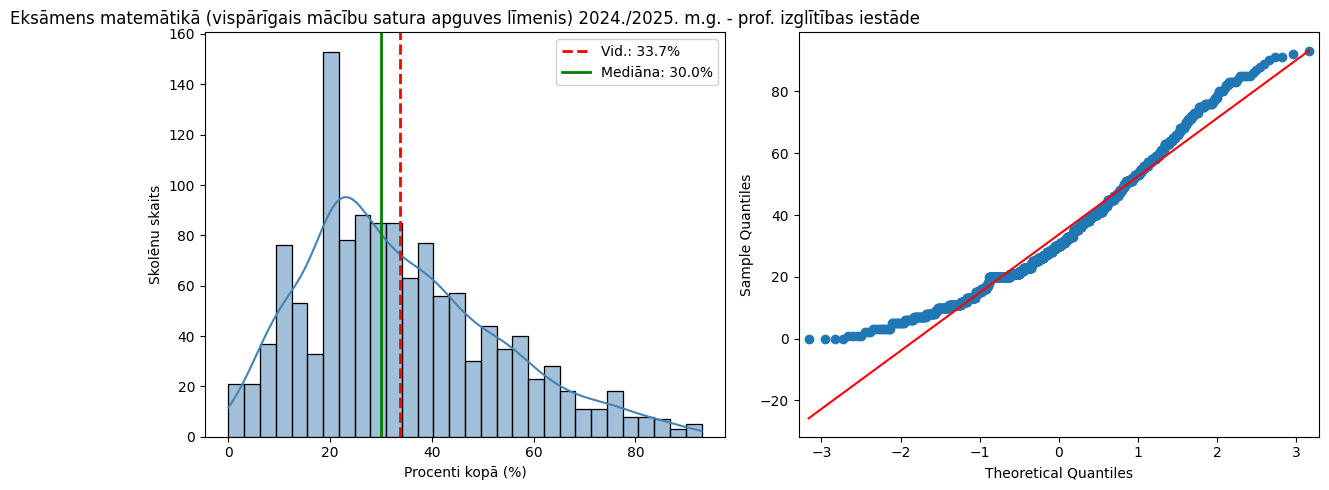


Shapiro test: Statistics=0.959, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =85.422, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.694, Kurtosis: 0.024

---------------
Skolas tips:  tālmācības vidusskola

---------------
Skolas tips:  valsts ģimnāzija

---------------
Skolas tips:  vidusskola


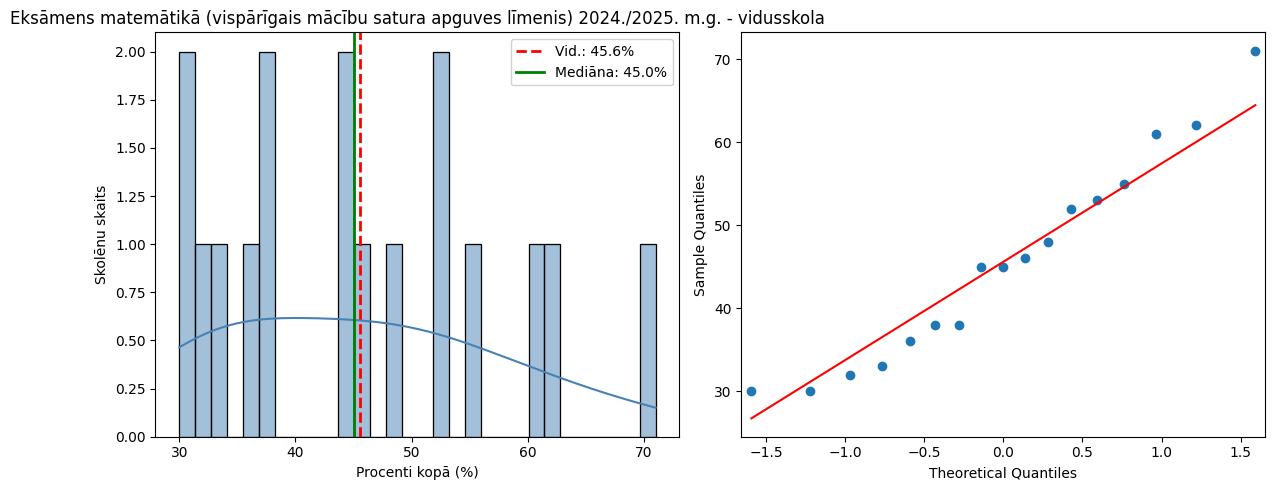


Shapiro test: Statistics=0.947, p=0.414,  normālais sadal. (fail to reject H0)
D’Agostino and Pearson’s test: Statistics =1.007, p=0.604,  normālais sadal. (fail to reject H0)
Skew: 0.432, Kurtosis: -0.747
_________________________
Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas urbanizācijas pakāpe:  Lauki


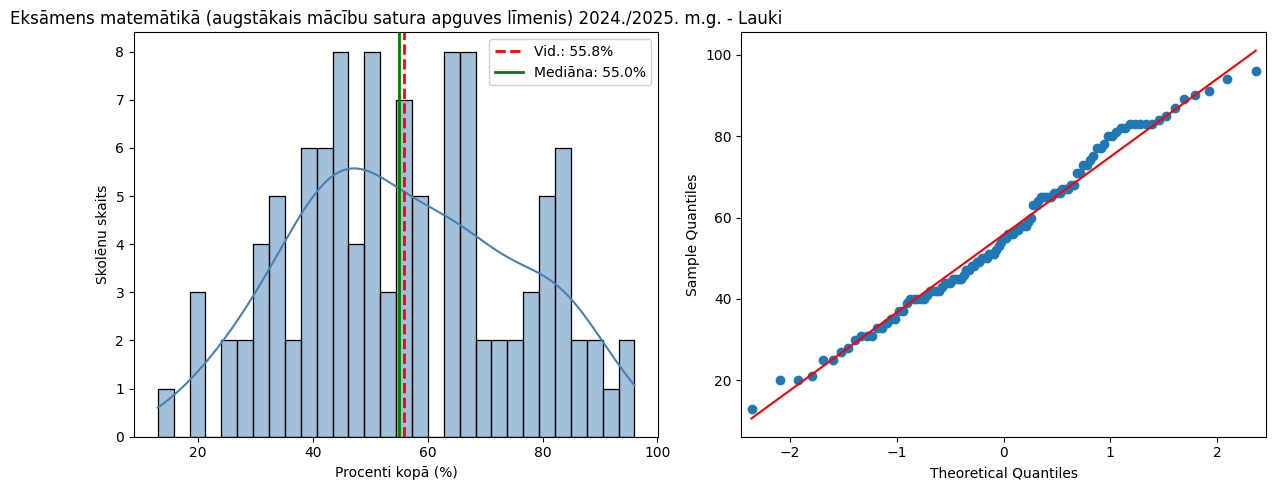


Shapiro test: Statistics=0.981, p=0.132,  normālais sadal. (fail to reject H0)
D’Agostino and Pearson’s test: Statistics =6.216, p=0.045,  nav normālais sadal. (reject H0)
Skew: 0.097, Kurtosis: -0.783

---------------
Skolas urbanizācijas pakāpe:  Novadu pilsētas


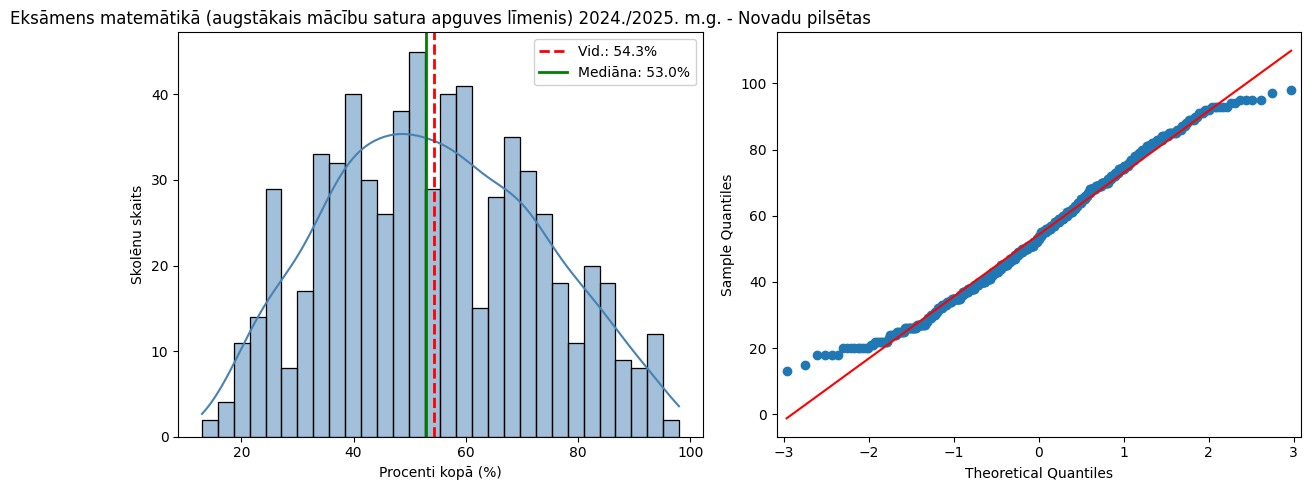


Shapiro test: Statistics=0.985, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =41.271, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.143, Kurtosis: -0.733

---------------
Skolas urbanizācijas pakāpe:  Rīga


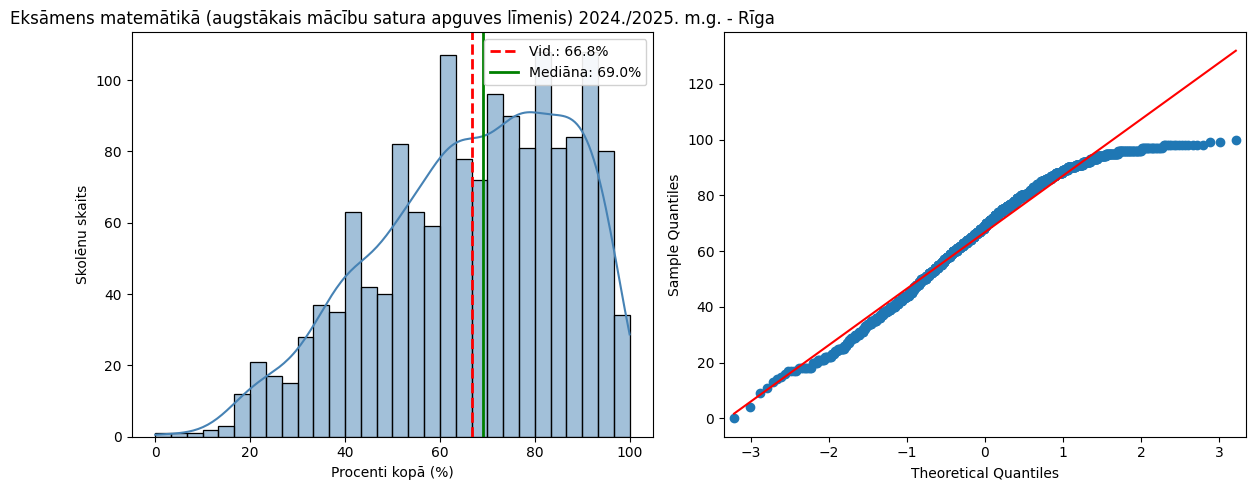


Shapiro test: Statistics=0.964, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =88.238, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.485, Kurtosis: -0.528

---------------
Skolas urbanizācijas pakāpe:  Tālmācības vidusskola


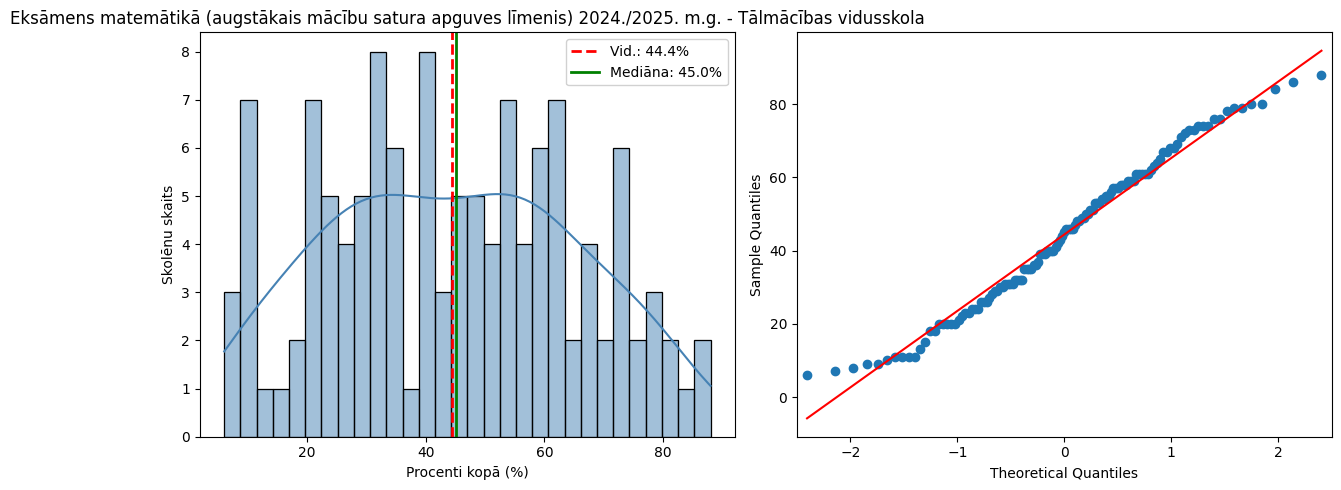


Shapiro test: Statistics=0.976, p=0.025,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =13.584, p=0.001,  nav normālais sadal. (reject H0)
Skew: 0.063, Kurtosis: -0.930

---------------
Skolas urbanizācijas pakāpe:  Valstspilsētas


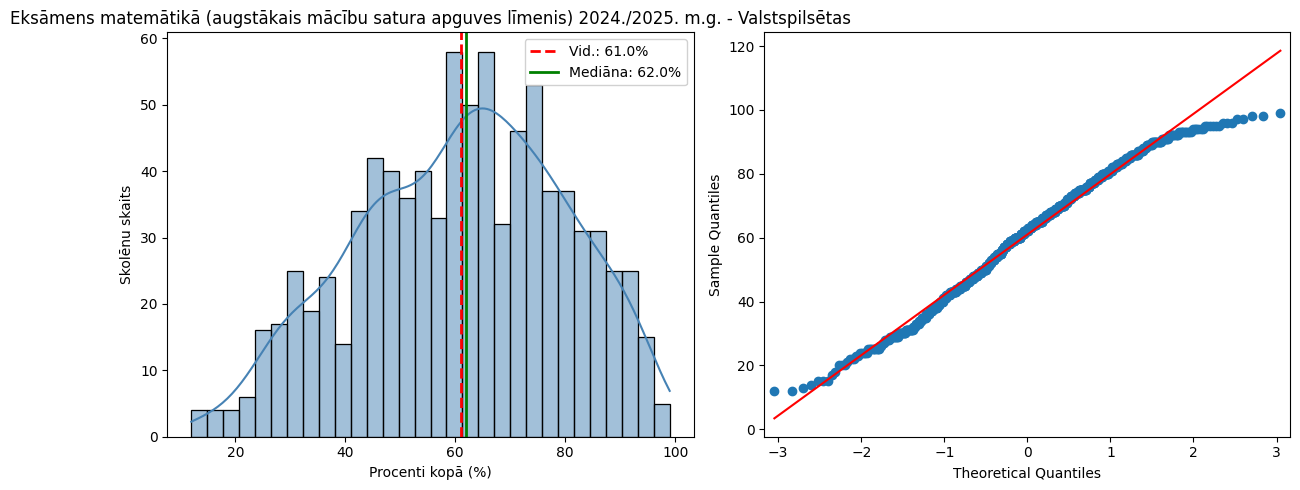


Shapiro test: Statistics=0.985, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =40.120, p=0.000,  nav normālais sadal. (reject H0)
Skew: -0.225, Kurtosis: -0.643
_________________________
Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas urbanizācijas pakāpe:  Lauki


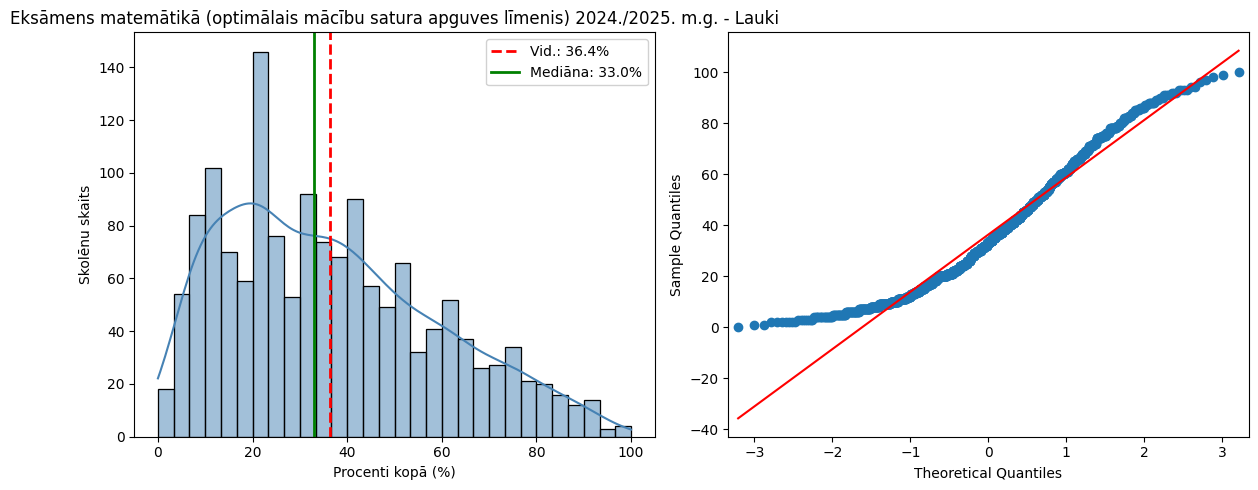


Shapiro test: Statistics=0.954, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =98.806, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.576, Kurtosis: -0.489

---------------
Skolas urbanizācijas pakāpe:  Novadu pilsētas


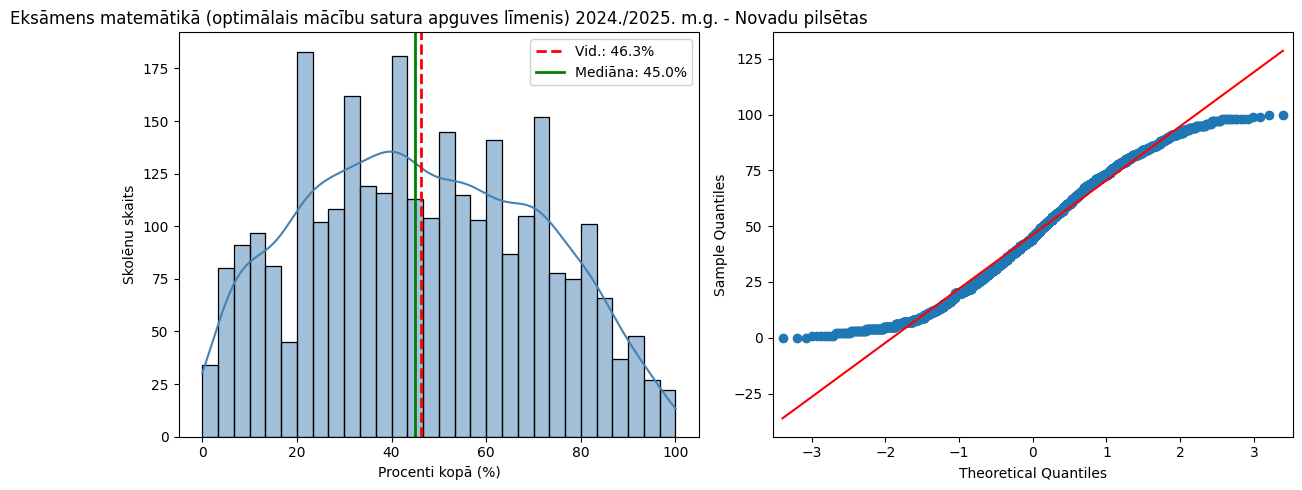


Shapiro test: Statistics=0.977, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =465.949, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.097, Kurtosis: -0.932

---------------
Skolas urbanizācijas pakāpe:  Rīga


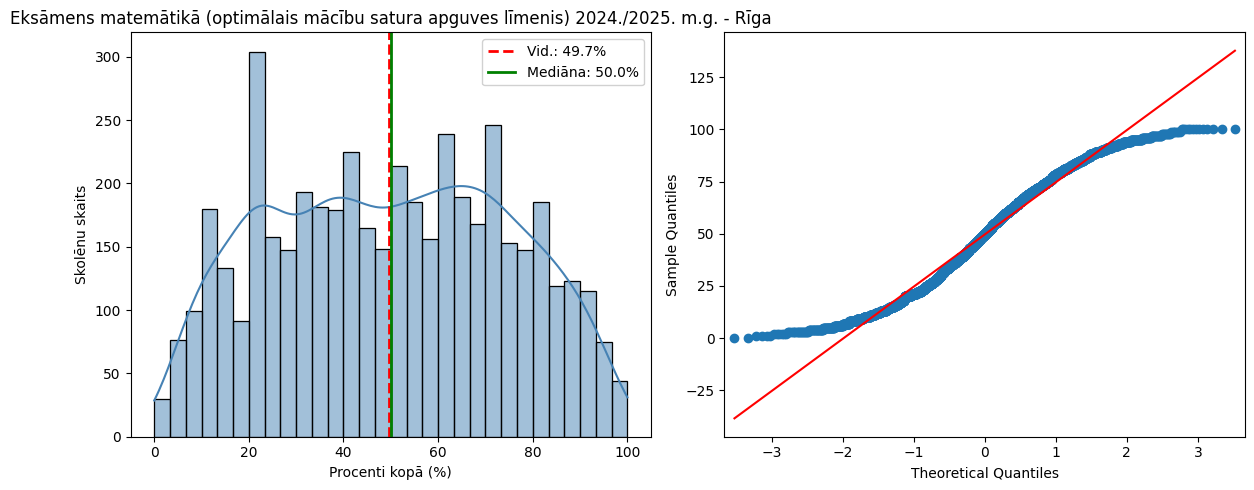


Shapiro test: Statistics=0.971, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =1444.926, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.011, Kurtosis: -1.056

---------------
Skolas urbanizācijas pakāpe:  Tālmācības vidusskola


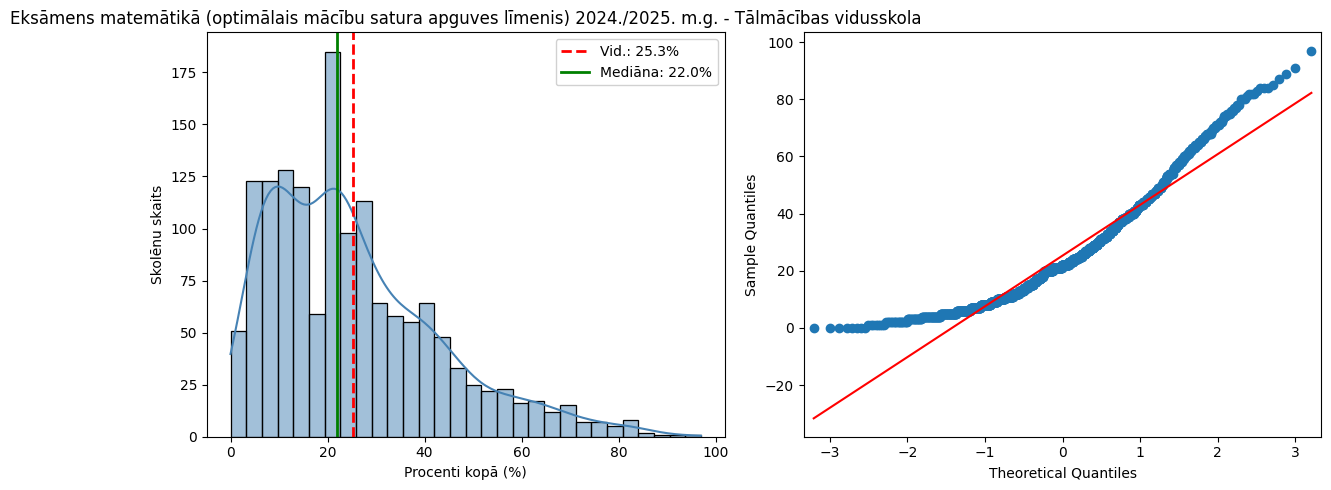


Shapiro test: Statistics=0.922, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =211.834, p=0.000,  nav normālais sadal. (reject H0)
Skew: 1.039, Kurtosis: 0.829

---------------
Skolas urbanizācijas pakāpe:  Valstspilsētas


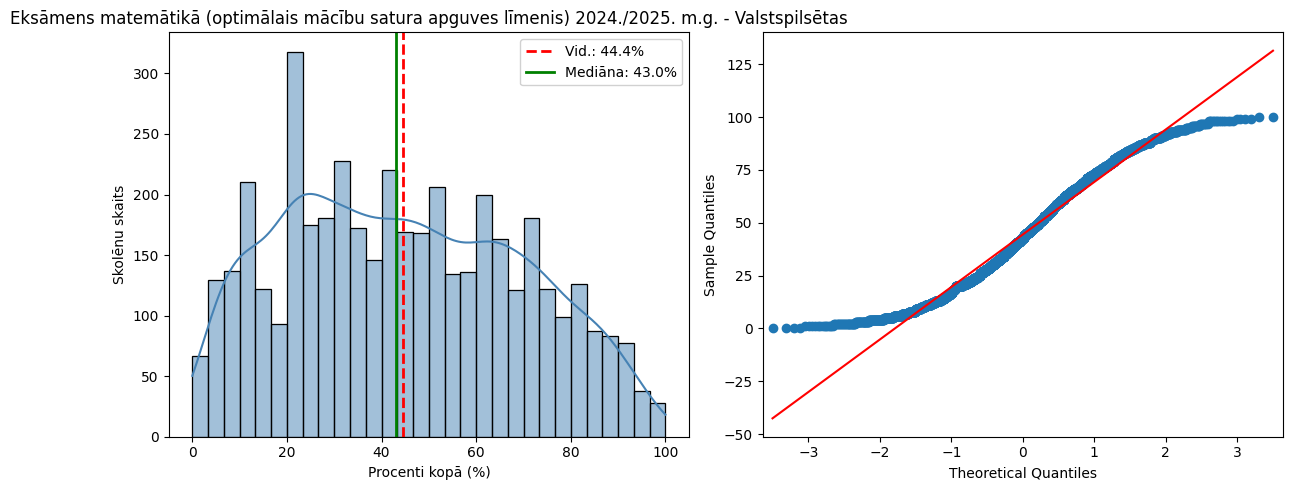


Shapiro test: Statistics=0.970, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =920.179, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.190, Kurtosis: -0.983
_________________________
Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g.

---------------
Skolas urbanizācijas pakāpe:  Lauki


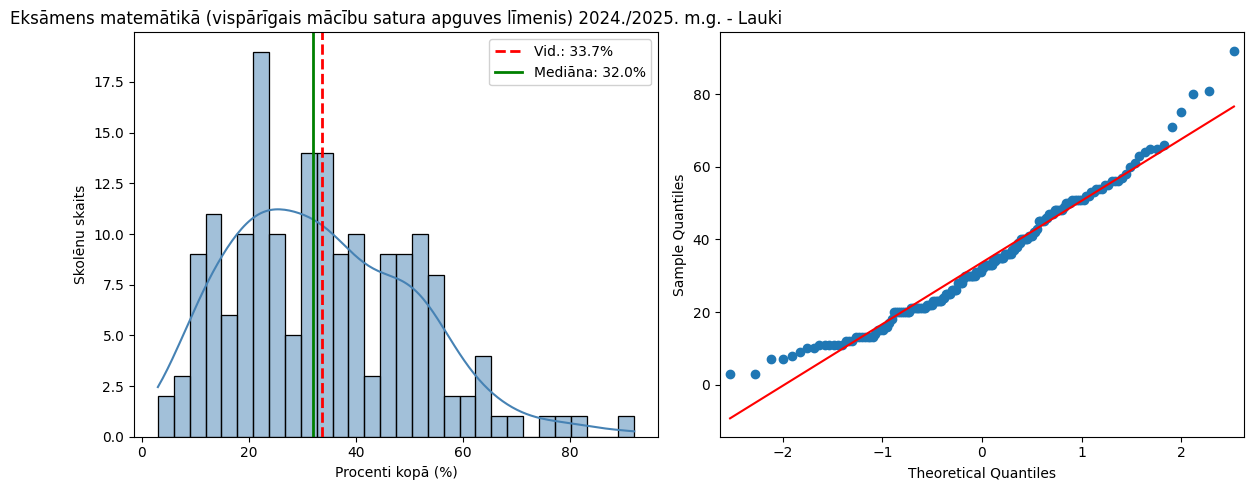


Shapiro test: Statistics=0.969, p=0.001,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =9.895, p=0.007,  nav normālais sadal. (reject H0)
Skew: 0.590, Kurtosis: 0.109

---------------
Skolas urbanizācijas pakāpe:  Novadu pilsētas


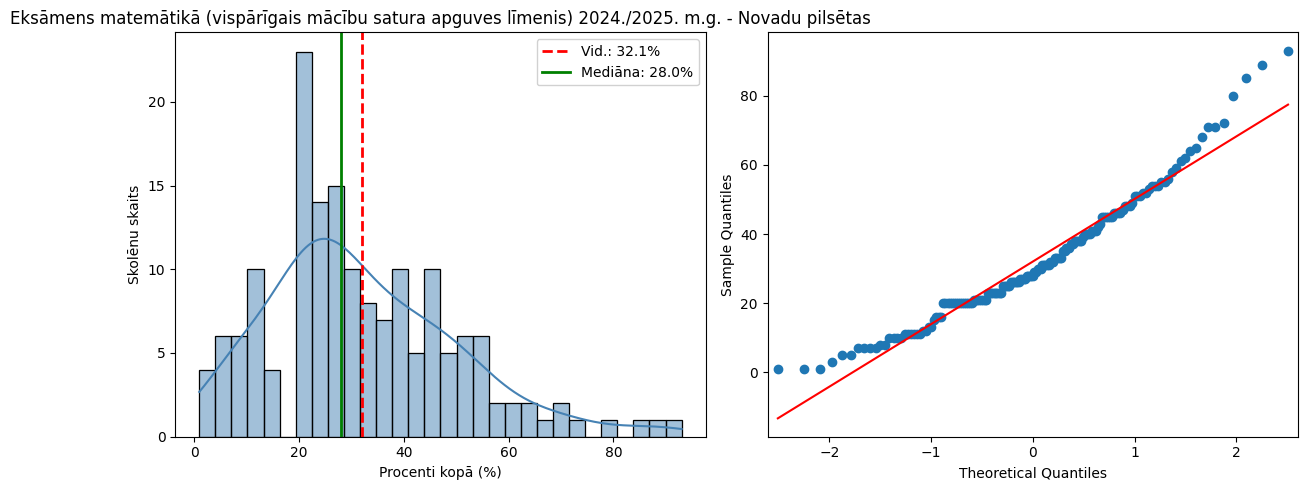


Shapiro test: Statistics=0.956, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =18.449, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.810, Kurtosis: 0.691

---------------
Skolas urbanizācijas pakāpe:  Rīga


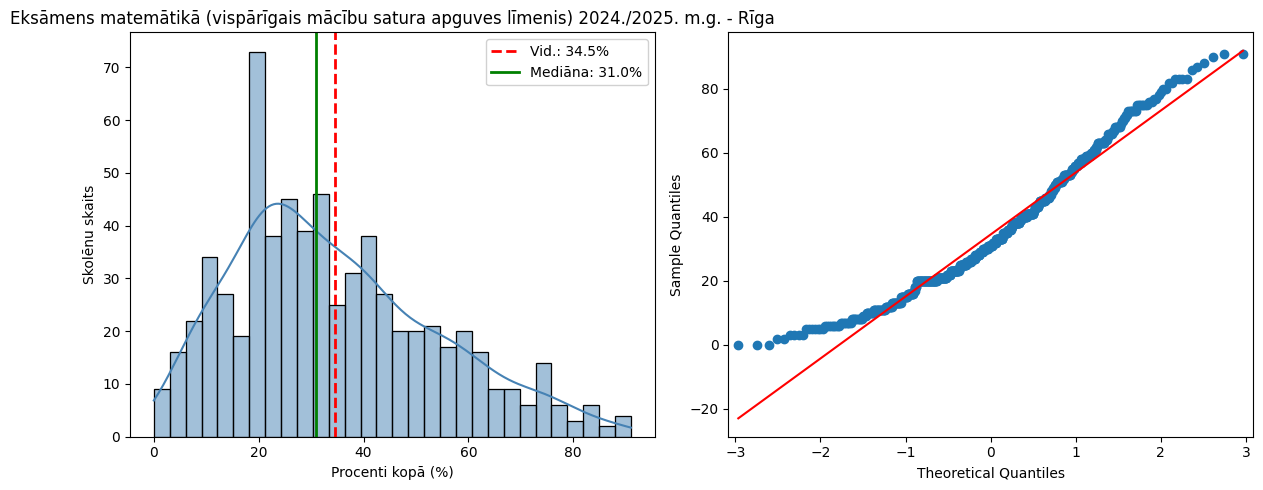


Shapiro test: Statistics=0.962, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =38.602, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.622, Kurtosis: -0.213

---------------
Skolas urbanizācijas pakāpe:  Tālmācības vidusskola

---------------
Skolas urbanizācijas pakāpe:  Valstspilsētas


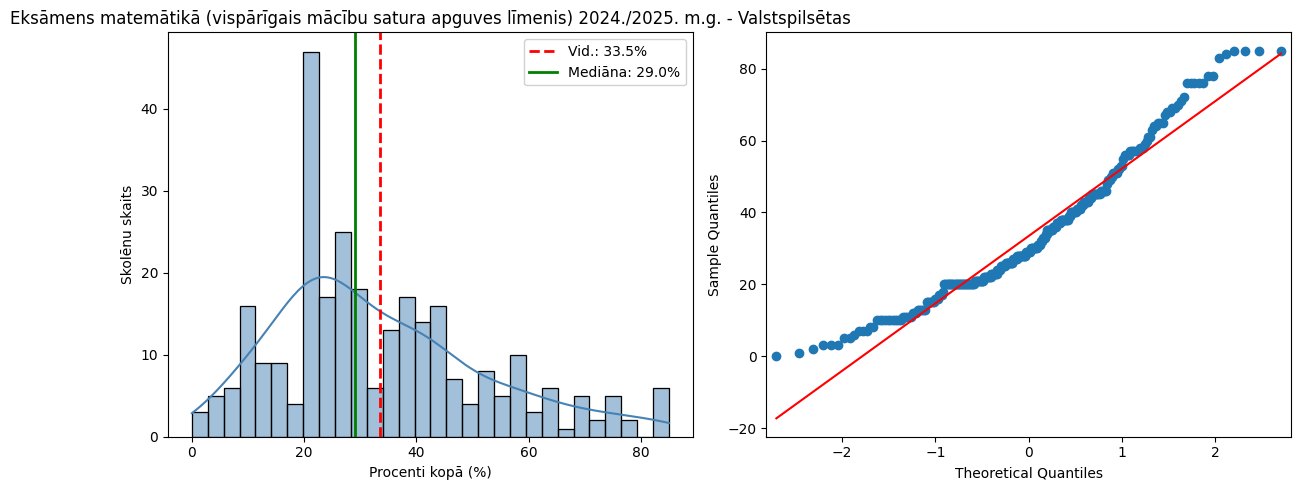


Shapiro test: Statistics=0.949, p=0.000,  nav normālais sadal. (reject H0)
D’Agostino and Pearson’s test: Statistics =23.843, p=0.000,  nav normālais sadal. (reject H0)
Skew: 0.759, Kurtosis: 0.086


In [18]:
exam_list=sorted(df['Norise'].dropna().unique())
unique_tips = sorted(df['Tips'].dropna().unique())
unique_urbanization = sorted(df['Urbanizācija'].dropna().unique())

for exam in exam_list:
    data=df[df['Norise']==exam]
    print("_________________________")
    print(exam)
    test_and_plot(data, 'Procenti kopā')

for exam in exam_list:
    data=df[df['Norise']==exam]
    print("_________________________")
    print(exam)
    for tips in unique_tips:
        data_t=data[data['Tips']==tips]
        print()
        print("---------------")
        print("Skolas tips: ", tips)
        if data_t['Procenti kopā'].empty:
            continue
        test_and_plot(data_t, 'Procenti kopā', tips)

for exam in exam_list:
    data=df[df['Norise']==exam]
    print("_________________________")
    print(exam)
    for urb in unique_urbanization:
        data_t=data[data['Urbanizācija']==urb]
        print()
        print("---------------")
        print("Skolas urbanizācijas pakāpe: ", urb)
        if data_t['Procenti kopā'].empty:
            continue
        test_and_plot(data_t, 'Procenti kopā', urb)

Kaut arī vairākām datu kopām vidējā vērtība un mediānas vērtība ir ļoti tuvas, tomēr praktiski visu datu kopu sadalījumi neatbilst normālajam sadalījumam, tādēļ turpmāk analīzē tiks izmantotas mediānas vērtības nevis vidējās vērtības.

### 2. Datu kopu vizualizācija

In [19]:
cols = [col for col in df.columns if 'Procenti' in col]
cols

['Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)',
 'Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)',
 'Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)',
 'Procenti Kompleksu problēmu risināšana (augstākā līmeņa saturs)',
 'Procenti kopā',
 'Procenti Zināšanas, izpratne un prasmes',
 'Procenti Kompleksu problēmu risināšana']

In [20]:
df['passed']=np.where(df['Procenti kopā']>=20, 1, np.where(df['Procenti kopā']<20, 0, np.nan))


In [ ]:
#Interaktīva vizualizācija datiem

app = Dash(__name__)

unique_tips = sorted(df['Tips'].dropna().unique())
unique_urbanization = sorted(df['Urbanizācija'].dropna().unique())
pv_unique = sorted(df['Pašvaldība'].dropna().unique())
pv_list=['Visa Latvija']+pv_unique
exam_list=sorted(df['Norise'].dropna().unique())
app.layout = html.Div([
    html.H4('Matemātikas eksāmens 2024./2025. m.g.'),
    html.Div([
        html.Label("Eksāmens:", style={'marginRight': '10px', 'fontWeight': 'bold', 'minWidth': '120px'}),
        dcc.Dropdown(id="eksamens", options=exam_list, value=exam_list[0], clearable=False, style={'flex': '1'})
    ], style={'display': 'flex', 'alignItems': 'center', 'marginBottom': '10px', 'backgroundColor': "#ffffff"}),
    
    #dcc.Dropdown(id="eksamens", options=exam_list, value=exam_list[0], clearable=False),
    #dcc.Dropdown(id="dropdown", options=cols, value='Procenti kopā', clearable=False),
    html.Div([
            html.Label("Eksāmena daļa:", style={'marginRight': '10px', 'fontWeight': 'bold', 'minWidth': '120px'}),
            dcc.Dropdown(id="dropdown", clearable=False, style={'flex': '1'})],
            style={'display': 'flex', 'alignItems': 'center', 'marginBottom': '10px', 'backgroundColor': "#ffffff"}),
    html.Div([
            html.Label("Parametrs:", style={'marginRight': '10px', 'fontWeight': 'bold', 'minWidth': '120px'}),
            dcc.Dropdown(id='dropdown_tu', options=[{'label': 'Skolas tips', 'value': 'Tips'}, {'label': 'Skolas urbanizācijas pakāpe', 'value': 'Urbanizācija'}], 
                     value='Tips', clearable=False, style={'flex': '1'})],
            style={'display': 'flex', 'alignItems': 'center', 'marginBottom': '10px', 'backgroundColor': "#ffffff"}),             
    html.Div([
                html.Label("Pašvaldība:", style={'marginRight': '10px', 'fontWeight': 'bold', 'minWidth': '120px'}),
            dcc.Dropdown(id='dropdown_pv', options=pv_list, value=pv_list[0], clearable=False, style={'flex': '1'})],
            style={'display': 'flex', 'alignItems': 'center', 'marginBottom': '10px', 'backgroundColor': "#ffffff"}),
    dcc.Graph(id="graph"),
    dcc.Graph(id='box_plots'),
    dcc.Graph(id='passed_plot'),
    dcc.Graph(id='exam_parts')
])


@app.callback(Output("dropdown", "options"), Output("dropdown", "value"),
    Input("eksamens", "value"))
def update_available_cols(eks):
    df_exam = df[df['Norise'] == eks]
    valid_cols = [c for c in cols if c in df_exam.columns and not df_exam[c].dropna().empty]
    default_val = 'Procenti kopā' if 'Procenti kopā' in valid_cols else (valid_cols[0] if valid_cols else None)
    return valid_cols, default_val

@app.callback(
    Output("graph", "figure"),
    Input("dropdown", "value"), Input("dropdown_tu", "value"), Input("dropdown_pv", "value"), Input("eksamens", "value"))
def update_bar_chart(col, cat, pv, eks):
    if pv=='Visa Latvija':
        df_avg = df[df['Norise']==eks].groupby(cat, as_index=False)[col].median()
    else:
        df_avg = df[(df['Pašvaldība']==pv) & (df['Norise']==eks)].groupby(cat, as_index=False)[col].median()
    fig = px.bar(df_avg, x=cat, y=col, title=f"Vērtējuma mediāna (%) - {col}", color_discrete_sequence=['#1f77b4'])
    if cat=='Tips':
        ctg_arr=unique_tips
        x_label='Skolas tips'
    else:
        ctg_arr=unique_urbanization
        x_label='Skolas urbanizācijas pakāpe'
    fig.update_xaxes(categoryorder='array', categoryarray=ctg_arr)
    fig.update_layout(yaxis_title="Vērtējuma mediāna (%)", template="plotly_white", xaxis_title=x_label)
    return fig

@app.callback(
    Output("box_plots", "figure"),
    Input("dropdown", "value"), Input("dropdown_tu", "value"), Input("dropdown_pv", "value"), Input("eksamens", "value"))
def update_box_chart(col, cat, pv, eks):
    if pv=='Visa Latvija':
        fig = px.box(df[df['Norise']==eks], x=cat, y=col, title=f"Vērtējumu sadalījums - {col}", color_discrete_sequence=['#1f77b4'])
    else:
        fig = px.box(df[(df['Pašvaldība']==pv) & (df['Norise']==eks)], x=cat, y=col, title=f"Vērtējumu sadalījums - {col}", color_discrete_sequence=['#1f77b4'])
    if cat=='Tips':
        ctg_arr=unique_tips
        x_label='Skolas tips'
    else:
        ctg_arr=unique_urbanization
        x_label='Skolas urbanizācijas pakāpe'
    fig.update_xaxes(categoryorder='array', categoryarray=ctg_arr)
    fig.update_layout(yaxis_title="Vērtējums (%)", template="plotly_white", xaxis_title=x_label)
    return fig

@app.callback (Output("passed_plot", "figure"), 
              Input("dropdown_tu", "value"), Input("dropdown_pv", "value"), Input("eksamens", "value"))
def update_passed_plot(cat, pv, eks):
    if pv == 'Visa Latvija':
        df_filtered = df[df['Norise'] == eks]
    else:
        df_filtered = df[(df['Pašvaldība'] == pv) & (df['Norise'] == eks)]
        
    if df_filtered.empty:
        return px.bar(title="Nav pieejamu datu")

    df_counts = (df_filtered.groupby([cat, 'passed'], as_index=False).size().rename(columns={'size': 'Skolēnu skaits'}))
    df_counts['Status'] = df_counts['passed'].map({1: 'Nokārtots (≥20%)', 0: 'Nenokārtots (<20%)'})
    if cat=='Tips':
        ctg_arr=unique_tips
        x_label='Skolas tips'
    else:
        ctg_arr=unique_urbanization
        x_label='Skolas urbanizācijas pakāpe'
    fig = px.bar(df_counts, x=cat, y='Skolēnu skaits', color='Status', title=f"Nokārtojušo un nenokārtojušo skolēnu skaits - sadalījums: {x_label}", barmode='stack',
        color_discrete_map={'Nenokārtots (<20%)': "#fa840e", 'Nokārtots (≥20%)': '#1f77b4'},
        category_orders={'Status': ['Nenokārtots (<20%)', 'Nokārtots (≥20%)']})
    summary_df = df_filtered.groupby(cat).agg(
        total=('passed', 'count'), passed_count=('passed', lambda x: (x == 1).sum()), failed_count=('passed', lambda x: (x == 0).sum())).reset_index()
    summary_df['top_label'] = summary_df.apply(lambda row: f"Nokārtoja: {row['passed_count']} | Nenokārtoja: {row['failed_count']}", axis=1)
    fig.add_trace(
        go.Scatter(x=summary_df[cat], y=summary_df['total'], mode='text', text=summary_df['top_label'], textposition='top center',
            textfont=dict(size=12, color='#333333', family='sans-serif', weight='bold'), showlegend=False))
    max_y = summary_df['total'].max()
    
    fig.update_layout(yaxis_title="Skolēnu skaits", yaxis_range=[0, max_y * 1.25], template="plotly_white", legend_title_text="", legend=dict(orientation="h", yanchor="top", y=1.1))
    
    
    fig.update_xaxes(categoryorder='array', categoryarray=ctg_arr)
    fig.update_layout(yaxis_title="Skolēnu skaits", template="plotly_white", legend_title_text="", xaxis_title=x_label)
    return fig

@app.callback(
    Output("exam_parts", "figure"),
    Input("dropdown", "options"), Input("dropdown_tu", "value"), Input("dropdown_pv", "value"), Input("eksamens", "value"))
def update_grouped_metrics_chart(dcols, cat, pv, eks):
    if pv == 'Visa Latvija':
        df_filtered = df[df['Norise'] == eks]
    else:
        df_filtered = df[(df['Pašvaldība'] == pv) & (df['Norise'] == eks)]
        
    dcols.remove('Procenti kopā')
    exam_parts=dcols
    custom_colors = ['#1f77b4', '#ff7f0e', "#2ca0a0", "#b3d627", '#9467bd', '#8c564b']
    df_grouped = df_filtered.groupby(cat)[exam_parts].median().reset_index()

    df_melted = pd.melt(df_grouped, id_vars=[cat], value_vars=exam_parts, var_name='Daļa', value_name='Mediāna')
    if cat=='Tips':
        ctg_arr=unique_tips
        x_label='Skolas tips'
    else:
        ctg_arr=unique_urbanization
        x_label='Skolas urbanizācijas pakāpe'
    fig = px.bar(df_melted, x=cat, y='Mediāna', color='Daļa', barmode='group', title=f"Eksāmena visu daļu mediānas - Sadalījums: {x_label}", color_discrete_sequence=custom_colors)
    
    
    fig.update_xaxes(categoryorder='array', categoryarray=ctg_arr)
   
    fig.update_layout(yaxis_title="Vērtējuma mediāna (%)", template="plotly_white", legend_title_text="Daļa",xaxis_title=x_label, 
                      legend=dict(orientation="h", yanchor="bottom", y=-0.5, xanchor="center", x=0.5))
    return fig

app.run(debug=True)

In [22]:
#Eksāmenu nokārtojušo un neokārtojušo skolēnu skaits
data_stat=df.groupby(['Norise'], as_index=False)['passed'].value_counts()
display(data_stat)

,Norise,passed,count
0,Eksāmens matemātikā (augstākais mācību satura ...,1.0,3256
1,Eksāmens matemātikā (augstākais mācību satura ...,0.0,50
2,Eksāmens matemātikā (optimālais mācību satura ...,1.0,12116
3,Eksāmens matemātikā (optimālais mācību satura ...,0.0,2786
4,Eksāmens matemātikā (vispārīgais mācību satura...,1.0,1048
5,Eksāmens matemātikā (vispārīgais mācību satura...,0.0,241


### 3. Datu statistiskā analīze

#### Vai var uzskatīt, ka vizuāli redzamās atšķirības Procentu vērtējuma mediānu sadalījumam pa skolas uzrbanizācijas pakāpēm ir statistiski nozīmīgas?

In [23]:
for exam in exam_list:
    data=df[df['Norise']==exam]
    #groups = [group['Procenti kopā'].dropna() for name, group in data.groupby('Tips')]
        
    #tips_groups = {name: group['Procenti kopā'].dropna() for name, group in data.groupby('Tips')}
    #groups = list(tips_groups.values())
    print(f"\n--- Eksāmens: {exam} ---")
    # Mediāna un skolēnu skaits
    dif_tests(data, 'Procenti kopā', 'Urbanizācija', 30)
    print("___________")


--- Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g. ---
                       median  count   IQR
Urbanizācija                              
Lauki                    55.0    109  26.0
Novadu pilsētas          53.0    672  29.0
Rīga                     69.0   1541  31.0
Tālmācības vidusskola    45.0    123  31.5
Valstspilsētas           62.0    861  28.0
Kruskal-Wallis p-value: 2.71475e-58,  Effect Size (ε²): 0.082 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0000,1.000,0.0,0.0054,0.112
Novadu pilsētas,1.0000,1.000,0.0,0.0010,0.000
Rīga,0.0000,0.000,1.0,0.0000,0.000
Tālmācības vidusskola,0.0054,0.001,0.0,1.0000,0.000
Valstspilsētas,0.1120,0.000,0.0,0.0000,1.000


___________

--- Eksāmens: Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g. ---
                       median  count   IQR
Urbanizācija                              
Lauki                    33.0   1497  33.0
Novadu pilsētas          45.0   2918  39.0
Rīga                     50.0   4667  42.0
Tālmācības vidusskola    22.0   1484  24.0
Valstspilsētas           43.0   4336  40.0
Kruskal-Wallis p-value: 7.32704e-273,  Effect Size (ε²): 0.085 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0,0.000,0.0,0.0,0.000
Novadu pilsētas,0.0,1.000,0.0,0.0,0.011
Rīga,0.0,0.000,1.0,0.0,0.000
Tālmācības vidusskola,0.0,0.000,0.0,1.0,0.000
Valstspilsētas,0.0,0.011,0.0,0.0,1.000


___________

--- Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g. ---
                 median  count   IQR
Urbanizācija                        
Lauki              32.0    175  25.5
Novadu pilsētas    28.0    163  24.0
Rīga               31.0    662  26.0
Valstspilsētas     29.0    289  24.0
Kruskal-Wallis p-value: 5.54800e-01,  Effect Size (ε²): -0.001 - no effect
  -> Nav statistiski nozīmīgu atšķirību.
___________


#tiem pāriem, kur p<0.05, ir novērojamas statistiski nozīmīgas atšķirības

#### Vai var uzskatīt, ka novērotās atšķirības starp skolu tipiem ir statistiski nozīmīgas?

In [24]:
for exam in exam_list:
    data=df[df['Norise']==exam]
    #groups = [group['Procenti kopā'].dropna() for name, group in data.groupby('Tips')]
        
    #tips_groups = {name: group['Procenti kopā'].dropna() for name, group in data.groupby('Tips')}
    #groups = list(tips_groups.values())
    print(f"\n--- Eksāmens: {exam} ---")
    # Mediāna un skolēnu skaits
    dif_tests(data, 'Procenti kopā', 'Tips', 30)
    print("______________")


--- Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g. ---
                          median  count   IQR
Tips                                         
augstskola                  44.0     10  11.0
prof. izglītības iestāde    50.0     95  27.5
tālmācības vidusskola       45.0    123  31.5
valsts ģimnāzija            72.0   1341  29.0
vidusskola                  58.0   1737  29.0
Kruskal-Wallis p-value: 1.82734e-74,  Effect Size (ε²): 0.104 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
prof. izglītības iestāde,1.0000,0.2332,0.0,0.0745
tālmācības vidusskola,0.2332,1.0000,0.0,0.0000
valsts ģimnāzija,0.0000,0.0000,1.0,0.0000
vidusskola,0.0745,0.0000,0.0,1.0000


______________

--- Eksāmens: Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g. ---
                          median  count   IQR
Tips                                         
augstskola                  22.0     42  24.5
prof. izglītības iestāde    28.0   4772  32.0
tālmācības vidusskola       22.0   1485  24.0
valsts ģimnāzija            70.0   2135  28.0
vidusskola                  48.0   6468  36.0
Kruskal-Wallis p-value: 0.00000e+00,  Effect Size (ε²): 0.265 - large
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,augstskola,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
augstskola,1.0,1.0,1.0,0.0,0.0
prof. izglītības iestāde,1.0,1.0,0.0,0.0,0.0
tālmācības vidusskola,1.0,0.0,1.0,0.0,0.0
valsts ģimnāzija,0.0,0.0,0.0,1.0,0.0
vidusskola,0.0,0.0,0.0,0.0,1.0


______________

--- Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g. ---
                          median  count   IQR
Tips                                         
prof. izglītības iestāde    30.0   1272  25.0
vidusskola                  45.0     17  17.0
Mann-Whitney p-value: 1.59320e-03, effect size: 0.445 large
______________


#### Vai var uzskatīt, ka vizuāli novērotās atšķirības starp eksāmenu daļām ir statistiski nozīmīgas (sadalījums pa urbanizācijas pakāpēm)?

In [25]:
cols = [col for col in df.columns if 'Procenti' in col]
exam_list=sorted(df['Norise'].dropna().unique())
unique_tips = sorted(df['Tips'].dropna().unique())

for exam in exam_list:

    df_filtered = df[df['Norise'] == exam]
    #exam_parts=cols.copy()    
    #exam_parts.remove('Procenti kopā')
    
    df_filtered.dropna(how='all', axis=1, inplace=True)
    exam_parts = [col for col in df_filtered.columns if 'Procenti' in col]
    exam_parts.remove('Procenti kopā')
    print()
    print(f"\n--- Eksāmens: {exam} ---")
    for eks_dala in exam_parts:
        print(f"\n--- Eksāmena daļa: {eks_dala}---")
        dif_tests(df_filtered, eks_dala, 'Urbanizācija', 30)
    print("__________________")



--- Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g. ---

--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)---
                       median  count   IQR
Urbanizācija                              
Lauki                    66.0    109  30.0
Novadu pilsētas          69.0    672  32.0
Rīga                     82.0   1541  27.0
Tālmācības vidusskola    61.0    123  36.5
Valstspilsētas           74.0    861  28.0
Kruskal-Wallis p-value: 2.63528e-53,  Effect Size (ε²): 0.075 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0000,1.0000,0.0,1.0000,0.0466
Novadu pilsētas,1.0000,1.0000,0.0,0.2581,0.0011
Rīga,0.0000,0.0000,1.0,0.0000,0.0000
Tālmācības vidusskola,1.0000,0.2581,0.0,1.0000,0.0001
Valstspilsētas,0.0466,0.0011,0.0,0.0001,1.0000



--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)---
                       median  count   IQR
Urbanizācija                              
Lauki                    44.0    109  38.0
Novadu pilsētas          42.0    672  38.0
Rīga                     68.0   1541  44.0
Tālmācības vidusskola    34.0    123  40.0
Valstspilsētas           54.0    861  42.0
Kruskal-Wallis p-value: 3.29264e-55,  Effect Size (ε²): 0.078 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0000,1.000,0.0,0.1762,0.1781
Novadu pilsētas,1.0000,1.000,0.0,0.1760,0.0000
Rīga,0.0000,0.000,1.0,0.0000,0.0000
Tālmācības vidusskola,0.1762,0.176,0.0,1.0000,0.0000
Valstspilsētas,0.1781,0.000,0.0,0.0000,1.0000



--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)---
                       median  count   IQR
Urbanizācija                              
Lauki                    60.0    109  38.0
Novadu pilsētas          54.0    672  31.0
Rīga                     71.0   1541  34.0
Tālmācības vidusskola    34.0    123  35.5
Valstspilsētas           65.0    861  32.0
Kruskal-Wallis p-value: 2.81704e-50,  Effect Size (ε²): 0.071 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0000,0.4609,0.0212,0.0,0.7174
Novadu pilsētas,0.4609,1.0000,0.0000,0.0,0.0000
Rīga,0.0212,0.0000,1.0000,0.0,0.0431
Tālmācības vidusskola,0.0000,0.0000,0.0000,1.0,0.0000
Valstspilsētas,0.7174,0.0000,0.0431,0.0,1.0000


... (3 outputs left out)

,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0,0.0000,0.0,0.0,0.0000
Novadu pilsētas,0.0,1.0000,0.0,0.0,0.0022
Rīga,0.0,0.0000,1.0,0.0,0.0000
Tālmācības vidusskola,0.0,0.0000,0.0,1.0,0.0000
Valstspilsētas,0.0,0.0022,0.0,0.0,1.0000



--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana---
                       median  count   IQR
Urbanizācija                              
Lauki                    14.0   1497  22.0
Novadu pilsētas          22.0   2918  28.0
Rīga                     24.0   4667  30.0
Tālmācības vidusskola     8.0   1484  12.0
Valstspilsētas           20.0   4336  30.0
Kruskal-Wallis p-value: 8.98271e-224,  Effect Size (ε²): 0.070 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,Lauki,Novadu pilsētas,Rīga,Tālmācības vidusskola,Valstspilsētas
Lauki,1.0,0.0,0.0,0.0,0.0
Novadu pilsētas,0.0,1.0,0.0,0.0,1.0
Rīga,0.0,0.0,1.0,0.0,0.0
Tālmācības vidusskola,0.0,0.0,0.0,1.0,0.0
Valstspilsētas,0.0,1.0,0.0,0.0,1.0


__________________


--- Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g. ---

--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes---
                 median  count   IQR
Urbanizācija                        
Lauki              38.0    175  29.0
Novadu pilsētas    35.0    163  25.0
Rīga               38.0    662  30.0
Valstspilsētas     36.0    289  26.0
Kruskal-Wallis p-value: 3.31127e-01,  Effect Size (ε²): 0.000 - no effect
  -> Nav statistiski nozīmīgu atšķirību.

--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana---
                 median  count   IQR
Urbanizācija                        
Lauki              10.0    175  20.0
Novadu pilsētas    12.0    163  20.0
Rīga               10.0    662  20.0
Valstspilsētas     10.0    289  17.0
Kruskal-Wallis p-value: 7.59707e-01,  Effect Size (ε²): -0.001 - no effect
  -> Nav statistiski nozīmīgu atšķirību.
__________________


#### Vai var uzskatīt, ka vizuāli novērotās atšķirības starp eksāmenu daļām ir statistiski nozīmīgas (sadalījums pa tipiem)?

In [26]:
cols = [col for col in df.columns if 'Procenti' in col]
exam_list=sorted(df['Norise'].dropna().unique())
unique_tips = sorted(df['Tips'].dropna().unique())

for exam in exam_list:

    df_filtered = df[df['Norise'] == exam]
    #exam_parts=cols.copy()    
    #exam_parts.remove('Procenti kopā')
    
    df_filtered.dropna(how='all', axis=1, inplace=True)
    exam_parts = [col for col in df_filtered.columns if 'Procenti' in col]
    exam_parts.remove('Procenti kopā')
    print()
    print(f"\n--- Eksāmens: {exam} ---")
    for eks_dala in exam_parts:
        print(f"\n--- Eksāmena daļa: {eks_dala}---")
        dif_tests(df_filtered, eks_dala, 'Tips', 30)
    print("______________")



--- Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g. ---

--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes (optimālā līmeņa saturs)---
                          median  count   IQR
Tips                                         
augstskola                  65.5     10  27.0
prof. izglītības iestāde    68.0     95  26.5
tālmācības vidusskola       61.0    123  36.5
valsts ģimnāzija            85.0   1341  25.0
vidusskola                  72.0   1737  29.0
Kruskal-Wallis p-value: 7.09453e-65,  Effect Size (ε²): 0.090 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
prof. izglītības iestāde,1.0000,1.0000,0.0,0.4553
tālmācības vidusskola,1.0000,1.0000,0.0,0.0032
valsts ģimnāzija,0.0000,0.0000,1.0,0.0000
vidusskola,0.4553,0.0032,0.0,1.0000



--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana (optimālā līmeņa saturs)---
                          median  count   IQR
Tips                                         
augstskola                  38.0     10  19.0
prof. izglītības iestāde    40.0     95  37.0
tālmācības vidusskola       34.0    123  40.0
valsts ģimnāzija            72.0   1341  42.0
vidusskola                  50.0   1737  42.0
Kruskal-Wallis p-value: 7.18034e-69,  Effect Size (ε²): 0.096 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
prof. izglītības iestāde,1.0000,1.0000,0.0,0.0643
tālmācības vidusskola,1.0000,1.0000,0.0,0.0001
valsts ģimnāzija,0.0000,0.0000,1.0,0.0000
vidusskola,0.0643,0.0001,0.0,1.0000



--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes (augstākā līmeņa saturs)---
                          median  count    IQR
Tips                                          
augstskola                  34.0     10  11.25
prof. izglītības iestāde    48.0     95  38.50
tālmācības vidusskola       34.0    123  35.50
valsts ģimnāzija            71.0   1341  31.00
vidusskola                  60.0   1737  37.00
Kruskal-Wallis p-value: 2.17376e-65,  Effect Size (ε²): 0.091 - medium
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
prof. izglītības iestāde,1.0000,0.0041,0.0,0.0118
tālmācības vidusskola,0.0041,1.0000,0.0,0.0000
valsts ģimnāzija,0.0000,0.0000,1.0,0.0000
vidusskola,0.0118,0.0000,0.0,1.0000


... (3 outputs left out)

,augstskola,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
augstskola,1.0,1.0,1.0,0.0,0.0
prof. izglītības iestāde,1.0,1.0,0.0,0.0,0.0
tālmācības vidusskola,1.0,0.0,1.0,0.0,0.0
valsts ģimnāzija,0.0,0.0,0.0,1.0,0.0
vidusskola,0.0,0.0,0.0,0.0,1.0



--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana---
                          median  count   IQR
Tips                                         
augstskola                   8.0     42  17.5
prof. izglītības iestāde    12.0   4772  20.0
tālmācības vidusskola        8.0   1485  12.0
valsts ģimnāzija            40.0   2135  36.0
vidusskola                  24.0   6468  28.0
Kruskal-Wallis p-value: 0.00000e+00,  Effect Size (ε²): 0.202 - large
  -> Statistiski nozīmīgas atšķīrības!

Pairwise Adjusted p-values (Dunn's Test):


,augstskola,prof. izglītības iestāde,tālmācības vidusskola,valsts ģimnāzija,vidusskola
augstskola,1.0,1.0,1.0,0.0,0.0
prof. izglītības iestāde,1.0,1.0,0.0,0.0,0.0
tālmācības vidusskola,1.0,0.0,1.0,0.0,0.0
valsts ģimnāzija,0.0,0.0,0.0,1.0,0.0
vidusskola,0.0,0.0,0.0,0.0,1.0


______________


--- Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g. ---

--- Eksāmena daļa: Procenti Zināšanas, izpratne un prasmes---
                          median  count   IQR
Tips                                         
prof. izglītības iestāde    36.0   1272  28.0
vidusskola                  56.0     17  18.0
Mann-Whitney p-value: 1.34658e-03, effect size: 0.452 large

--- Eksāmena daļa: Procenti Kompleksu problēmu risināšana---
                          median  count   IQR
Tips                                         
prof. izglītības iestāde    10.0   1272  20.0
vidusskola                  20.0     17  10.0
Mann-Whitney p-value: 1.06471e-02, effect size: 0.358 medium
______________


#### Skolu un pašvaldību top 10

In [27]:
exam_list=sorted(df['Norise'].dropna().unique())
for exam in exam_list:
    muni_rankings = rank_function(df[df['Norise']==exam], group_col='Pašvaldība')
    print(f"Eksāmens: {exam}")
    print("Top 10 Pašvaldības:")
    display(muni_rankings[['Rank', 'Pašvaldība', 'student_count', 'median_score', 'pass_ratio', 'rank_score', 'school_types']].head(10))
    print("______________")

Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g.
Top 10 Pašvaldības:


,Rank,Pašvaldība,student_count,median_score,pass_ratio,rank_score,school_types
0,1,Dobeles novads,28,80.0,1.000000,0.900000,valsts ģimnāzija
1,2,Daugavpils,177,70.0,1.000000,0.850000,"valsts ģimnāzija, vidusskola"
2,3,Rēzekne,109,68.0,1.000000,0.840000,"valsts ģimnāzija, vidusskola"
3,4,Valmieras novads,61,68.0,1.000000,0.840000,"prof. izglītības iestāde, valsts ģimnāzija, vi..."
4,5,Rīga,1600,68.0,0.981875,0.830938,"augstskola, prof. izglītības iestāde, tālmācīb..."
5,6,Ķekavas novads,34,66.0,1.000000,0.830000,vidusskola
6,7,Valkas novads,11,65.0,1.000000,0.825000,vidusskola
7,8,Siguldas novads,24,62.0,1.000000,0.810000,"valsts ģimnāzija, vidusskola"
8,9,Salaspils novads,12,61.5,1.000000,0.807500,vidusskola
9,10,Ventspils,76,61.0,1.000000,0.805000,"valsts ģimnāzija, vidusskola"


______________
Eksāmens: Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g.
Top 10 Pašvaldības:


,Rank,Pašvaldība,student_count,median_score,pass_ratio,rank_score,school_types
0,1,Ādažu novads,79,61.0,1.000000,0.805000,vidusskola
1,2,Līvānu novads,56,58.0,0.982143,0.781071,vidusskola
2,3,Olaines novads,46,60.5,0.956522,0.780761,vidusskola
3,4,Preiļu novads,57,56.0,1.000000,0.780000,"valsts ģimnāzija, vidusskola"
4,5,Salaspils novads,36,54.5,1.000000,0.772500,vidusskola
5,6,Siguldas novads,173,61.0,0.924855,0.767428,"valsts ģimnāzija, vidusskola"
6,7,Ķekavas novads,104,55.5,0.942308,0.748654,vidusskola
7,8,Madonas novads,149,53.0,0.966443,0.748221,"valsts ģimnāzija, vidusskola"
8,9,Valkas novads,31,49.0,1.000000,0.745000,vidusskola
9,10,Mārupes novads,206,58.5,0.902913,0.743956,"prof. izglītības iestāde, valsts ģimnāzija, vi..."


______________
Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g.
Top 10 Pašvaldības:


,Rank,Pašvaldība,student_count,median_score,pass_ratio,rank_score,school_types
0,1,Balvu novads,17,45.0,1.000000,0.725000,vidusskola
1,2,Cēsu novads,21,46.0,0.904762,0.682381,prof. izglītības iestāde
2,3,Valmieras novads,79,38.0,0.911392,0.645696,prof. izglītības iestāde
3,4,Ogres novads,104,35.5,0.913462,0.634231,prof. izglītības iestāde
4,5,Preiļu novads,47,29.0,0.851064,0.570532,prof. izglītības iestāde
5,6,Rīga,662,31.0,0.808157,0.559079,prof. izglītības iestāde
6,7,Ventspils,13,26.0,0.846154,0.553077,prof. izglītības iestāde
7,8,Saldus novads,31,26.0,0.838710,0.549355,prof. izglītības iestāde
8,9,Daugavpils,85,28.0,0.800000,0.540000,prof. izglītības iestāde
9,10,Jelgava,83,26.0,0.795181,0.527590,prof. izglītības iestāde


______________


In [28]:
exam_list=sorted(df['Norise'].dropna().unique())
for exam in exam_list:
    print(f"Eksāmens: {exam}")
    school_rankings = rank_function(df[df['Norise']==exam], group_col='Iestāde')
    print("\nTop 10 mācību iestādes:")
    display(school_rankings[['Rank', 'Iestāde', 'student_count', 'median_score', 'pass_ratio', 'rank_score', 'school_types']].head(10))
    print("______________")

Eksāmens: Eksāmens matemātikā (augstākais mācību satura apguves līmenis) 2024./2025. m.g.

Top 10 mācību iestādes:


,Rank,Iestāde,student_count,median_score,pass_ratio,rank_score,school_types
0,1,RTU inženierzinātņu vidusskola,24,94.0,1.0,0.9700,vidusskola
1,2,Rīgas Valsts 1. ģimnāzija,198,92.0,1.0,0.9600,valsts ģimnāzija
2,3,Daugavpils Tehnoloģiju vidusskola - licejs,44,85.5,1.0,0.9275,vidusskola
3,4,Siguldas Valsts ģimnāzija,16,82.5,1.0,0.9125,valsts ģimnāzija
4,5,Rīgas Valsts 2. ģimnāzija,129,82.0,1.0,0.9100,valsts ģimnāzija
5,6,Rīgas 40. vidusskola,23,81.0,1.0,0.9050,vidusskola
6,7,Dobeles Valsts ģimnāzija,28,80.0,1.0,0.9000,valsts ģimnāzija
7,8,Rīgas Valsts klasiskā ģimnāzija,37,80.0,1.0,0.9000,valsts ģimnāzija
8,9,Rīgas Centra humanitārā vidusskola,21,77.0,1.0,0.8850,vidusskola
9,10,Valmieras Valsts ģimnāzija,21,74.0,1.0,0.8700,valsts ģimnāzija


______________
Eksāmens: Eksāmens matemātikā (optimālais mācību satura apguves līmenis) 2024./2025. m.g.

Top 10 mācību iestādes:


,Rank,Iestāde,student_count,median_score,pass_ratio,rank_score,school_types
0,1,Rīgas Valsts 1. ģimnāzija,38,96.0,1.0,0.9800,valsts ģimnāzija
1,2,Rīgas Valsts 3. ģimnāzija,187,86.0,1.0,0.9300,valsts ģimnāzija
2,3,Siguldas Valsts ģimnāzija,81,83.0,1.0,0.9150,valsts ģimnāzija
3,4,Daugavpils Tehnoloģiju vidusskola - licejs,55,82.0,1.0,0.9100,vidusskola
4,5,Rīgas Valsts 2. ģimnāzija,37,81.0,1.0,0.9050,valsts ģimnāzija
5,6,Rīgas Franču licejs,71,80.0,1.0,0.9000,vidusskola
6,7,Rīgas Āgenskalna Valsts ģimnāzija,25,75.0,1.0,0.8750,valsts ģimnāzija
7,8,Daugavpils Valsts ģimnāzija,77,75.0,1.0,0.8750,valsts ģimnāzija
8,9,Jūrmalas Valsts ģimnāzija,22,75.0,1.0,0.8750,valsts ģimnāzija
9,10,Jelgavas valstspilsētas pašvaldības izglītības...,140,74.5,1.0,0.8725,valsts ģimnāzija


______________
Eksāmens: Eksāmens matemātikā (vispārīgais mācību satura apguves līmenis) 2024./2025. m.g.

Top 10 mācību iestādes:


,Rank,Iestāde,student_count,median_score,pass_ratio,rank_score,school_types
0,1,"Mākslu izglītības kompetences centrs ""Nacionāl...",12,75.5,1.000000,0.877500,prof. izglītības iestāde
1,2,Jāzepa Mediņa Rīgas Mūzikas vidusskola,33,63.0,1.000000,0.815000,prof. izglītības iestāde
2,3,"Mākslu izglītības kompetences centrs ""Nacionāl...",12,57.0,1.000000,0.785000,prof. izglītības iestāde
3,4,Balvu profesionālā un vispārizglītojošā viduss...,17,45.0,1.000000,0.725000,vidusskola
4,5,Alfrēda Kalniņa Cēsu mūzikas vidusskola,10,53.0,0.900000,0.715000,prof. izglītības iestāde
5,6,Valmieras Dizaina un mākslas vidusskola,48,45.0,0.958333,0.704167,prof. izglītības iestāde
6,7,Vidzemes Tehnoloģiju un dizaina tehnikuma prog...,11,40.0,0.909091,0.654545,prof. izglītības iestāde
7,8,Ogres tehnikums,104,35.5,0.913462,0.634231,prof. izglītības iestāde
8,9,Rīgas Valsts tehnikums,24,37.0,0.875000,0.622500,prof. izglītības iestāde
9,10,Rīgas Tirdzniecības profesionālā vidusskola,20,31.0,0.900000,0.605000,prof. izglītības iestāde


______________


Darba autore: Zanda Gavare